# TP-G2: do code-model maps track search *order* or *storage*?

**Artifact** `art_ho7tqaOyBjkN` is iteration 10 of the TP-G line. It continues iteration 9's `art_VVA3P0ocZNA2` / `art_8nXdw3_lDAll`.

**Research context.** Ask an LLM to "implement a path search algorithm" and it almost always writes BFS. Is the model's answer just the *average* of what it has seen, and can a prompt push it somewhere new? Earlier rounds banned the five most common answers in the prompt (BFS, DFS, IDDFS, A*, greedy best-first). They then asked where the *survivor* programs land on the model's internal map of path-search programs: at the **edge** of the banned region, or **opposite** it. Those rounds read the program-state geometry as "the path-search manifold". This round tests what that geometry actually encodes.

**Question.** Does the program-state geometry separate programs by **expansion discipline** once the **storage container** is held fixed by design?
- Disciplines: FIFO level order (BFSO), LIFO order (DFSO), goal-heuristic order (HEUR), path-cost order (COST), relaxation rounds (RELAX), random order (RAND).
- Containers: deque, list, recursion (CALL), heapq, 2-D arrays (GRID2D), set.

**Design.**
- *Stimuli.* Qwen3-32B (OpenRouter, thinking off) wrote name-scrubbed grid path programs for a pre-committed 6 × 6 discipline × container factorial. 24 cells are implementable, with 12 verified programs each (287 frozen programs). Prompts describe the mechanics step by step and never name an algorithm. Every program passed the hidden test suites, AST container checks and tracer/runtime discipline checks.
- *States.* Each program is teacher-forced through Qwen3-8B (bf16, block 17) and Qwen3-32B (NF4, block 33). The readout **R1** is the mean hidden state over the code tokens.
- **G1 (representational similarity analysis).** The partial Spearman correlation of the program-state dissimilarity matrix (RDM) with the discipline RDM, controlling for the container RDM (ρ_dc), and the reverse (ρ_cd). Inference uses a program bootstrap and restricted permutations. Baselines are a bag-of-tokens model (E0) and a random-init network (RANDNET), with sensitivities S1–S11.
- **G2 (placement).** A kNN-geodesic frame of the factorial cells plus a 10-algorithm catalogue. Survivor families are placed out of sample and called EDGE or OPPOSITE relative to the banned classes.

**Full-run results (N = 287).**
- **G1 is INDETERMINATE on both models.** Discipline is encoded: ρ_dc = 0.226 (8B) and 0.285 (32B), p = 0.0005, above E0 (0.17 / 0.16) and RANDNET (0.07). Container is encoded more strongly (ρ_cd = 0.300 / 0.414), and token surface more strongly than either.
- **G2.**
  - Covert BFS/DFS programs land on banned classes 99% / 98% of the time.
  - Grid Bellman-Ford survivors land nearest the RELAX cells (30/32 and 31/32).
  - Unit-weight Dijkstra lands nearest COST-HEAP.
- The geometry is correlational: there is no causal or steering claim.

### What this notebook runs
`method.py` is a stage orchestrator: setup → r0 → tests → generate → assemble → freeze → states → g1 / g2 / robust → outputs → figures → audit. The generation and state-extraction stages need an OpenRouter key and GPUs running Qwen3-8B / Qwen3-32B. Their output ships precomputed for a curated subset of **96 of the 287 frozen factorial programs** (4 per cell), and this notebook runs the analysis stages on it.

| section | stage | what runs here |
|---|---|---|
| 1 | `method.py` | the orchestrator and its stage plan (shown, not executed) |
| 2 | frozen modules | `v10.py`, `geometry.py`, `r0.py`, `g1.py`, `g2.py`, embedded **unchanged** |
| 3–4 | `g1` | `analysis.run_g1` on both models (primary test + S1–S11) and the pre-registered verdict |
| 5 | `g2` | the G2 frame built from the 96 programs: class geometry and leave-one-out placement |
| 6 | `figures` | F1/F2 (PCA, Isomap, MDS in activation coordinates), F5 (G1 bars), F7 (layer curve) |
| 7 | `audit` | stdlib-only re-derivation of ρ_dc / ρ_cd |
| 8 | summary | demo subset vs full run, plus the G2 frame maps |

**Lossless state encoding.** The demo file stores, for each state slice X (96 programs × 4096 or 5120 hidden units), the coordinates C = U·diag(s) from the thin SVD X = U·diag(s)·Vᵀ. Because C·Cᵀ = X·Xᵀ, every cosine distance (G1) and every Euclidean distance (G2, kNN geodesics, PCA) between the 96 programs is unchanged, to within 3·10⁻⁸. So the analysis below runs on exactly the geometry the models produced, only for fewer programs.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT pre-installed on Colab, always install (the artifact logs through loguru)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, scikit-learn -- pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'scikit-learn==1.6.1')

In [2]:
from __future__ import annotations

# ---- import blocks of method.py / src/analysis.py / src/figures.py (original) ----
import os

for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[_v] = "1"                 # one BLAS thread per process: the box has 6 CPUs

import csv
import json
import math
import multiprocessing as mp
import subprocess
import sys
import time
import warnings
from collections import Counter
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path
from typing import Any

import numpy as np
from loguru import logger

# ---- notebook additions: inline figures (figures.py used the non-interactive Agg backend) ----
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-10/experiment-55/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
ex = data["examples"]
per_cell = Counter(e["metadata_cell"] for e in ex)
print(f"{len(ex)} programs from {data['metadata']['source_dataset']}")
print(f"{len(per_cell)} cells, {sorted(set(per_cell.values()))} programs per cell; selection: {data['metadata']['selection']}")
print("state slices per program:", {t: sorted(ex[0][f'states_{t}']) for t in ('8b', '32b')})
print(f"coordinate dim per slice: {len(ex[0]['states_8b']['R1_b17'])}; max cosine-distance error of the encoding: "
      f"{data['metadata']['max_abs_cosine_distance_error']:.1e}")
print(f"\nexample {ex[0]['metadata_uid']} ({ex[0]['metadata_discipline']} x {ex[0]['metadata_container']})")
print("prompt:", ex[0]["input"][:400], "...")
print("program (name-scrubbed):\n" + ex[0]["output"][:600] + "\n...")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
96 programs from tpg2_factorial (full_method_out.json; 287 frozen programs, 24 cells)
24 cells, [4] programs per cell; selection: 4 programs per cell x 24 cells = 96; greedy diversity over wording, context variant, repair status and heuristic key; ties by frozen order
state slices per program: {'8b': ['E0', 'R1_b11', 'R1_b13', 'R1_b15', 'R1_b17', 'R1_b19', 'R1_b21', 'R1_b23', 'R1_b25', 'R1_b26', 'R1_b9', 'R1g_b17', 'R2_b17', 'R3_b17', 'RANDNET_R1_b17', 'ctx2_R1_b17'], '32b': ['E0', 'R1_b21', 'R1_b25', 'R1_b29', 'R1_b31', 'R1_b33', 'R1_b35', 'R1_b37', 'R1_b39', 'R1g_b33', 'R2_b33', 'R3_b33']}
coordinate dim per slice: 96; max cosine-distance error of the encoding: 3.3e-08

example BFSO-DEQUE|A|6 (BFSO x DEQUE)
prompt: CELL BFSO-DEQUE (FIFO / level order x DEQUE); prompt:
Write the search as follows. Keep the frontier in a collections.deque. Add every newly discovered cell at the right end with append() a

## Configuration

Every tunable parameter of the analysis is set here. The comments give the original full-run values. The defaults below are the full-run values except `CLASS_FLOOR`: the demo frame has 4 programs per cell, so the floor of 10 programs per class would empty it. On the 96-program subset the whole analysis takes under a minute on a CPU (about 20 s for G1 on both models), plus package installation. Lower `N_BOOT` / `N_PERM` for a quicker look, or set `QUICK = True` to use the artifact's own `--quick` settings.

In [5]:
# ---- demo configuration (original full-run values in the comments) ----
MODEL_TAGS = ["8b", "32b"]   # original: ["8b", "32b"]  (Qwen3-8B bf16 block 17, Qwen3-32B NF4 block 33)
QUICK = False                # original CLI flag --quick (200 boots / 400 perms / 100 variant boots / 50 S2 boots)
N_BOOT = 1000                # original 1000: program-bootstrap resamples (95% percentile CIs; also cell-cluster)
N_PERM = 2000                # original 2000: restricted within-stratum permutations (p-value floor 1 / (N_PERM + 1))
N_BOOT_VARIANTS = 200        # original 200: bootstrap resamples for each S3-S10 sensitivity variant
N_BOOT_S2 = 100              # original 100: bootstrap resamples of the S2 rank-regression semi-partial r's
K_PRIMARY = 15               # original 15: kNN degree of the geodesic graph (G2 frame, S6 geodesic D_S, Isomap)
CLASS_FLOOR = 4              # original 10: min programs per frame class (the demo data holds 4 programs per cell)
LOO_WORKERS = 2              # original 2: worker processes for the G2 frame leave-one-out

## 1. The stage orchestrator (`method.py`)

`method.py` runs each stage as a subprocess on a module in `src/`. The cell below is the original file: docstring, stage table and `main`. Only `ROOT` changes, because a notebook has no `__file__`; the imports are in the imports cell above. `main()` is **not called**, because the stage scripts and the GPU/API inputs are not part of the demo. The printout shows where each stage is reproduced in this notebook, or what it would need.

In [6]:
"""TP-G2 (iteration 10): do program-state maps of code LMs track expansion DISCIPLINE or storage CONTAINER, and where
do the survivor families of the five-name ban land on a frame built from a discipline x container factorial?

Method (G1): Qwen3-32B (OpenRouter, thinking off) writes name-scrubbed grid path programs for a pre-committed 6 x 6
discipline x container factorial (24 implementable cells, 12 verified programs each). Each program is teacher-forced
under iteration 9's neutral-twin context through an exact truncated decoder and read out with iteration 9's frozen
readout R1 (mean over code tokens) at block 17 of Qwen3-8B bf16 and block 33 of Qwen3-32B NF4. The program-state RDM
is fitted with partial Spearman correlations against the discipline RDM controlling container (rho_dc) and the
reverse (rho_cd); restricted (within-stratum) permutations and a program bootstrap give the inference.
Baselines (same pipeline, same programs): E0 = bag-of-tokens embedding mean; RANDNET = random-init truncated Qwen3-8B;
token-surface / length / context RDMs fitted jointly (rank regression); the 3 x 4 crossed core.
Method (G2): survivor families (unit-weight Dijkstra, grid Bellman-Ford, coordinate-key heaps, random frontiers, raster
sweeps, set frontiers, covert BFS/DFS) are placed out of sample on the factorial + catalogue frame with iteration 9's
kNN-geodesic landing code (also on container-held-fixed and discipline-held-fixed subframes).

Stages (each resumable; every module lives in src/):
  setup      copy inputs with sha256 (scripts/setup_inputs.py)
  r0         reproduction gate on iteration 9's frozen frames (src/r0.py)
  tests      verifier unit tests (tests/test_verifiers.py) and analysis unit tests (tests/test_analysis.py)
  generate   smoke -> pilot -> COMMIT1a -> wave A/B with repair -> paraphrase fallback (src/gen.py)
  assemble   placed-program families (src/assemble.py)
  freeze     factorial / top-up freeze (src/freeze.py)
  states     Qwen3-8B, RANDNET, Qwen3-32B states (src/extract.py)
  g1 | g2 | robust   analyses (src/analysis.py), outputs (src/outputs.py), figures (src/figures.py)
  audit      stdlib re-derivation (audit/rederive.py)
Usage: .venv/bin/python method.py <stage> [...]   ('all-analysis' runs g1, g2, robust, outputs, figures, audit)
"""

# (imports: see the imports cell at the top of the notebook)

ROOT = Path.cwd()                      # original: Path(__file__).resolve().parent (a notebook has no __file__)
PY = sys.executable
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[_v] = "1"

STAGES: dict[str, list[list[str]]] = {
    "setup": [["python3", "scripts/setup_inputs.py"]],
    "r0": [[PY, "src/r0.py"]],
    "tests": [[PY, "tests/test_verifiers.py"], [PY, "tests/test_analysis.py"]],
    "generate": [[PY, "src/gen.py", "smoke"], [PY, "src/gen.py", "pilot"], [PY, "src/gen.py", "main"],
                 [PY, "src/gen.py", "paraphrase"]],
    "assemble": [[PY, "src/assemble.py"]],
    "freeze": [[PY, "src/freeze.py", "factorial"], [PY, "src/freeze.py", "topups"]],
    "states": [[PY, "src/extract.py", "8b", "repro", "placed", "refs", "factorial", "factorial_ctx2", "topups"],
               [PY, "src/extract.py", "randnet", "factorial"],
               [PY, "src/extract.py", "32b", "repro", "placed", "refs", "factorial", "topups"]],
    "order": [[PY, "scripts/order_matrix.py"]],
    "g1": [[PY, "src/analysis.py", "g1", "8b", "32b"]],
    "g2": [[PY, "src/analysis.py", "g2", "8b", "32b"]],
    "robust": [[PY, "src/analysis.py", "robust", "8b", "32b"]],
    "outputs": [[PY, "src/outputs.py"]],
    "figures": [[PY, "src/figures.py"]],
    "audit": [["python3", "-I", "audit/rederive.py"]],
}
STAGES["all-analysis"] = STAGES["g1"] + STAGES["g2"] + STAGES["robust"] + STAGES["outputs"] + STAGES["figures"] + \
    STAGES["audit"]


@logger.catch(reraise=True)
def main() -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    (ROOT / "logs").mkdir(exist_ok=True)
    logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")
    stages = sys.argv[1:] or ["all-analysis"]
    for st in stages:
        if st not in STAGES:
            raise SystemExit(f"unknown stage {st}; choose from {sorted(STAGES)}")
        for cmd in STAGES[st]:
            logger.info(f"[{st}] {' '.join(cmd)}")
            r = subprocess.run(cmd, cwd=ROOT)
            if r.returncode != 0:
                logger.error(f"[{st}] failed with exit code {r.returncode}")
                raise SystemExit(r.returncode)



# ---- notebook: where each stage runs (main() is NOT called) ----
IN_NOTEBOOK = {"g1": "section 4 (run_g1 on the 96-program subset)",
               "g2": "section 5 (frame + class geometry + leave-one-out)",
               "outputs": "section 4 (outputs.g1_verdict only)",
               "figures": "section 6 (F1, F2, F5, F7)",
               "audit": "section 7 (stdlib re-derivation, G1 part)"}
NEEDS = {"setup": "the prior artifacts' files", "r0": "iteration 9's frozen states", "tests": "vendor/ harnesses, tests/",
         "generate": "an OpenRouter API key", "assemble": "prior rounds' survivor programs",
         "freeze": "data/programs_v10.jsonl", "states": "a GPU + Qwen3-8B / Qwen3-32B weights",
         "order": "the tracer probes (vendor/, probes/)", "robust": "the 351 placed survivor programs",
         "all-analysis": "everything above"}
for st, cmds in STAGES.items():
    where = IN_NOTEBOOK.get(st) or f"not run here: needs {NEEDS.get(st, '?')}"
    print(f"{st:<13}{' | '.join(' '.join(c[1:]) for c in cmds)[:60]:<61}-> {where}")

setup        scripts/setup_inputs.py                                      -> not run here: needs the prior artifacts' files
r0           src/r0.py                                                    -> not run here: needs iteration 9's frozen states
tests        tests/test_verifiers.py | tests/test_analysis.py             -> not run here: needs vendor/ harnesses, tests/
generate     src/gen.py smoke | src/gen.py pilot | src/gen.py main | src/ -> not run here: needs an OpenRouter API key
assemble     src/assemble.py                                              -> not run here: needs prior rounds' survivor programs
freeze       src/freeze.py factorial | src/freeze.py topups               -> not run here: needs data/programs_v10.jsonl
states       src/extract.py 8b repro placed refs factorial factorial_ctx2 -> not run here: needs a GPU + Qwen3-8B / Qwen3-32B weights
order        scripts/order_matrix.py                                      -> not run here: needs the tracer probes (vendor/, 

## 2. Frozen library modules (unchanged)

The analysis code was frozen before any G1/G2 output existed (commitment COMMIT1c in the artifact's hash chain). The next cells write these modules, character for character, to `tpg2/src/` with `%%writefile` and import them, so the notebook runs exactly the code that produced the paper's numbers:

| module | role | used here |
|---|---|---|
| `v10.py` | constants (banned / non-banned split, model pins and blocks, k, class floor), JSON I/O, hash-chain helpers | constants and `write_json` |
| `common.py` | iteration 9's shared module; **excerpt**: only `CANON_ORDER`, the one name `geometry.py` imports | `CANON_ORDER` |
| `geometry.py` | iteration 9's geometry: kNN graph, geodesics, class g values, classical MDS | `geodesics`, `g_values`, `classify`, `classical_mds`, `stress1` |
| `r0.py` | the R0 reproduction gate | `oos` only (the gate itself reads iteration 9's states) |
| `g1.py` | G1 statistics | everything |
| `g2.py` | G2 frame, placement and leave-one-out | `Frame`, `loo`, `disc_of`, `is_banned` |

On import, `v10.py` creates `tpg2/{data,results,predictions,logs,figures,cache}`. The notebook writes its JSON, CSV and figure outputs to `tpg2/results/` and `tpg2/figures/`, as the original pipeline does.

In [7]:
SRC = Path("tpg2/src").resolve()        # module folder (ROOT of the frozen code = tpg2/)
SRC.mkdir(parents=True, exist_ok=True)
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))        # also inherited by the spawned LOO workers of g2.loo
print("frozen modules go to", SRC.relative_to(Path.cwd()))

frozen modules go to tpg2/src


**`src/v10.py`**: the shared constants of this round. The banned split is `BANNED_ALGS` / `BANNED_DISC` and the non-banned split is `NONBANNED_*`. `MODELS` pins each model's revision, its kept blocks and its primary block (17 for Qwen3-8B, 33 for Qwen3-32B). `K_PRIMARY = 15` and `CLASS_FLOOR = 10` are also set here. The commitment-chain helpers (`commit`, `verify_chain`) are kept but not used.

In [8]:
%%writefile tpg2/src/v10.py
#!/usr/bin/env python3
"""TP-G2 shared constants: hash-chained commitments (genesis sha256('iter10_tpg2')), paths, frozen settings,
the banned / non-banned split, the model pins and block choices for this round."""

from __future__ import annotations

import fcntl
import hashlib
import json
import os
from datetime import datetime, timezone
from pathlib import Path
from typing import Any

ROOT = Path(__file__).resolve().parent.parent
DATA, RESULTS, PRED, LOGS, FIGS = ROOT / "data", ROOT / "results", ROOT / "predictions", ROOT / "logs", ROOT / "figures"
STATES_V10 = ROOT / "cache" / "states_v10"
COMMIT_LOG = ROOT / "commitments.log"
GENESIS = hashlib.sha256(b"iter10_tpg2").hexdigest()
for _d in (DATA, RESULTS, PRED, LOGS, FIGS, STATES_V10):
    _d.mkdir(parents=True, exist_ok=True)

# Prior artifacts are read through ONE relative constant: the published repository lays every artifact out as a
# sibling folder named by its artifact id (override the parent with TPG_DEPS_DIR, or one artifact with TPG_DEP_<id>).
DEPS_DIR = Path(os.environ.get("TPG_DEPS_DIR", str(ROOT.parent)))


def dep(art_id: str) -> Path:
    return Path(os.environ.get("TPG_DEP_" + art_id.replace("-", "_"), str(DEPS_DIR / art_id)))


E46 = dep("art_VVA3P0ocZNA2")                    # iteration-9 gen_art_experiment_46
E46_STATES = E46 / "cache" / "states"            # read in place (sha256 in inputs_manifest.json)
IN46 = ROOT / "inputs" / "art_VVA3P0ocZNA2"
IN45 = ROOT / "inputs" / "art_8nXdw3_lDAll"
IN44 = ROOT / "inputs" / "art_R-HSmXq2t97f"
DSET = dep("art_j3Rm_lr2nzR6")                   # declared dependency (iteration-1 dataset)

CANON = ["bfs", "dfs", "bibfs", "iddfs", "astar", "gbfs", "dijkstra_unit", "idastar", "jps", "biastar"]
BANNED_ALGS = ["bfs", "dfs", "iddfs", "astar", "gbfs"]
NONBANNED_ALGS = ["dijkstra_unit", "idastar", "bibfs", "jps", "biastar"]
BANNED_DISC = ["BFSO", "DFSO", "HEUR"]
NONBANNED_DISC = ["COST", "RELAX", "RAND"]
CLASS_FLOOR = 10
K_PRIMARY, K_SECOND = 15, 10

M8 = {"tag": "8b", "repo": "Qwen/Qwen3-8B", "revision": "b968826d9c46dd6066d109eabc6255188de91218",
      "precision": "bf16", "n_layers": 36, "n_keep": 27, "blocks": [9, 11, 13, 15, 17, 19, 21, 23, 25, 26],
      "primary_block": 17, "hidden": 4096, "engine": "HF bf16 Qwen3-8B"}
M32 = {"tag": "32b", "repo": "unsloth/Qwen3-32B-bnb-4bit", "revision": "7f721e74a6a8cc9ee352f7e49303a2c1705f9083",
       "precision": "nf4", "n_layers": 64, "n_keep": 40, "blocks": [21, 25, 29, 31, 33, 35, 37, 39],
       "primary_block": 33, "hidden": 5120, "engine": "HF nf4 unsloth/Qwen3-32B-bnb-4bit truncated"}
MODELS = {"8b": M8, "32b": M32}
READOUTS = ["R1", "R1g", "R2", "R3"]


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with Path(p).open("rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + f".tmp{os.getpid()}")
    tmp.write_text(json.dumps(obj, indent=indent, ensure_ascii=False, default=_default))
    tmp.replace(p)


def _default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, Path):
        return str(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    for ln in p.read_text().splitlines():
        ln = ln.strip()
        if ln:
            try:
                out.append(json.loads(ln))
            except json.JSONDecodeError:
                continue
    return out


def append_jsonl(p: Path, row: dict[str, Any]) -> None:
    with Path(p).open("a") as fh:
        fcntl.flock(fh, fcntl.LOCK_EX)
        fh.write(json.dumps(row, ensure_ascii=False, default=_default) + "\n")
        fcntl.flock(fh, fcntl.LOCK_UN)


def commit(payload: Path, label: str, note: str = "") -> dict[str, Any]:
    """Append {i, label, utc, prev_line_sha256, payload_sha256, payload_path, note} to commitments.log; line 0 chains
    on GENESIS = sha256('iter10_tpg2'), every later line on the sha256 of the previous line's exact text."""
    lines = COMMIT_LOG.read_text().splitlines() if COMMIT_LOG.exists() else []
    prev = sha256_text(lines[-1]) if lines else GENESIS
    e = {"i": len(lines), "label": label, "utc": utc_now(), "prev_line_sha256": prev,
         "payload_sha256": sha256_file(payload), "payload_path": str(Path(payload).resolve().relative_to(ROOT)),
         "note": note}
    with COMMIT_LOG.open("a") as fh:
        fh.write(json.dumps(e, sort_keys=True) + "\n")
    return e


def verify_chain() -> dict[str, Any]:
    if not COMMIT_LOG.exists():
        return {"ok": False, "problems": ["no commitments.log"]}
    prev = GENESIS
    problems, labels = [], []
    for i, ln in enumerate(COMMIT_LOG.read_text().splitlines()):
        e = json.loads(ln)
        labels.append((e["label"], e["utc"]))
        if e["prev_line_sha256"] != prev:
            problems.append(f"line {i}: chain break")
        p = ROOT / e["payload_path"]
        if not p.exists():
            problems.append(f"line {i}: payload missing")
        elif sha256_file(p) != e["payload_sha256"]:
            problems.append(f"line {i}: payload changed ({e['payload_path']})")
        prev = sha256_text(ln)
    return {"ok": not problems, "problems": problems, "entries": labels}


def commit_time(label: str) -> str | None:
    if not COMMIT_LOG.exists():
        return None
    for ln in COMMIT_LOG.read_text().splitlines():
        e = json.loads(ln)
        if e["label"] == label:
            return e["utc"]
    return None


def deviation(code: str, text: str) -> None:
    p = RESULTS / "deviations.json"
    devs = read_json(p) if p.exists() else []
    if not any(d["code"] == code for d in devs):
        devs.append({"code": code, "text": text, "utc": utc_now()})
        write_json(p, devs)


def ledger(milestone: str, **kw: Any) -> None:
    append_jsonl(LOGS / "time_ledger.jsonl", {"milestone": milestone, "utc": utc_now(), **kw})

Writing tpg2/src/v10.py


**`src/common.py` (excerpt)**: iteration 9's `common.py` also sets up dependency paths, the frozen task text and I/O helpers, and creates folders on import. `geometry.py` imports only `CANON_ORDER` from it, so only that constant is reproduced here.

In [9]:
%%writefile tpg2/src/common.py
"""EXCERPT of iteration 9's src/common.py: CANON_ORDER, the only name geometry.py imports from it."""

CANON_ORDER = ["bfs", "dfs", "bibfs", "iddfs", "astar", "gbfs", "dijkstra_unit", "idastar", "jps", "biastar"]

Writing tpg2/src/common.py


**`src/geometry.py`** (reused unchanged from iteration 9):
- `knn_graph` builds a symmetrised kNN distance graph and joins any disconnected components by their shortest inter-component edges.
- `geodesics` takes Dijkstra shortest paths through that graph.
- `g_values` gives, for each non-banned class, the minimum over banned classes of the mean geodesic.
- `classify` calls a class EDGE or OPPOSITE relative to the median.
- `classical_mds` and `stress1` draw and score the maps.

In [10]:
%%writefile tpg2/src/geometry.py
#!/usr/bin/env python3
"""Stage 7 G2/G3 geometry in actual activation coordinates (no summary bars).

G2 L*: per block, standardise -> PCA(64) fit in fold -> multinomial logistic regression (C=1); grouped 10-fold CV with
groups = (template t, alias j) pairs (a held-out paraphrase is held out for all 10 algorithms); score = balanced
accuracy; L* = argmax, ties within 0.01 -> block nearest depth 0.5 (all at ceiling -> nearest depth 0.5 among ceiling).
G3 M1 at L*: PCA 2D (EVR), classical MDS on the 300 points and the 10 centroids (Kruskal stress-1), Isomap k in
{5,10,15} on the symmetrised kNN distance graph (shortest inter-component edges added if disconnected, component count
recorded), geodesics via scipy shortest_path. g_k(a) = min over b in B of mean geodesic distance over pairs (points of
a, points of b) (iteration-7 top5geo.py definition). Classes: EDGE g < median, MIDDLE g == median, OPPOSITE g > median
over the 5 non-banned algorithms. Reliability: split-half Spearman of 10x10 mean-geodesic matrices; 1,000 bootstrap
resamples of paraphrase groups -> class and nearest-banned stability.
"""

from __future__ import annotations

from typing import Any

import numpy as np
from loguru import logger
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components, shortest_path
from scipy.spatial.distance import cdist, pdist, squareform
from scipy.stats import spearmanr

from common import CANON_ORDER


# ---------------------------------------------------------------------------------------------- layer selection
def layer_curve(X_blocks: np.ndarray, labels: np.ndarray, groups: np.ndarray, blocks: list[int],
                sel_blocks: list[int], n_layers: int) -> dict[str, Any]:
    from sklearn.decomposition import PCA
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import balanced_accuracy_score
    from sklearn.model_selection import GroupKFold
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    curve = {}
    preds = {}
    gkf = GroupKFold(n_splits=10)
    for b in sel_blocks:
        X = X_blocks[:, blocks.index(b)].astype(np.float64)
        pred = np.empty(len(labels), dtype=object)
        for tr, te in gkf.split(X, labels, groups):
            clf = make_pipeline(StandardScaler(), PCA(n_components=min(64, len(tr) - 1), random_state=0),
                                LogisticRegression(C=1.0, max_iter=3000))
            clf.fit(X[tr], labels[tr])
            pred[te] = clf.predict(X[te])
        curve[b] = float(balanced_accuracy_score(labels, pred.astype(str)))
        preds[b] = [str(x) for x in pred]
    best = max(curve.values())
    near = [b for b in sel_blocks if best - curve[b] <= 0.01]
    L = min(near, key=lambda b: (abs((b + 1) / n_layers - 0.5), b))
    ceiling = [b for b in sel_blocks if curve[b] >= 0.9999]
    rule = "argmax (ties within 0.01 -> nearest depth 0.5)"
    if len(ceiling) == len(sel_blocks):
        L = min(ceiling, key=lambda b: (abs((b + 1) / n_layers - 0.5), b))
        rule = "all blocks at ceiling -> nearest depth 0.5"
    return {"curve": curve, "L_star": int(L), "best": best, "tied_blocks": near, "rule": rule,
            "depth_of_L_star": (L + 1) / n_layers, "cv_pred_at_L": preds[L]}


# ---------------------------------------------------------------------------------------------- graphs
def knn_graph(X: np.ndarray, k: int) -> tuple[csr_matrix, int, int]:
    """Symmetrised kNN distance graph; disconnected components joined by their shortest inter-component edges
    (as sklearn Isomap does). Returns (graph, components before joining, edges added)."""
    D = squareform(pdist(X))
    n = len(X)
    D[D == 0] = 1e-12                       # duplicates (bootstrap) stay connected
    np.fill_diagonal(D, 0.0)
    W = np.zeros((n, n))
    order = np.argsort(D, axis=1)
    for i in range(n):
        nb = [j for j in order[i] if j != i][:k]
        W[i, nb] = D[i, nb]
    W = np.maximum(W, W.T)
    G = csr_matrix(W)
    ncomp, lab = connected_components(G, directed=False)
    added = 0
    if ncomp > 1:
        for a in range(ncomp):
            for b in range(a + 1, ncomp):
                ia, ib = np.where(lab == a)[0], np.where(lab == b)[0]
                sub = D[np.ix_(ia, ib)]
                i, j = np.unravel_index(np.argmin(sub), sub.shape)
                W[ia[i], ib[j]] = W[ib[j], ia[i]] = max(sub[i, j], 1e-12)
                added += 1
        G = csr_matrix(W)
    return G, int(ncomp), added


def geodesics(X: np.ndarray, k: int) -> tuple[np.ndarray, dict[str, Any]]:
    Xu = X.copy()
    # exact duplicates (bootstrap resamples) -> jitter-free handling: dedupe by index mapping
    G, ncomp, added = knn_graph(Xu, k)
    geo = shortest_path(G, method="D", directed=False)
    return geo, {"k": k, "components_before_join": ncomp, "edges_added": added, "connected": ncomp == 1,
                 "finite": bool(np.isfinite(geo).all())}


def class_matrix(geo: np.ndarray, labels: np.ndarray, classes: list[str]) -> np.ndarray:
    M = np.zeros((len(classes), len(classes)))
    for i, a in enumerate(classes):
        for j, b in enumerate(classes):
            sub = geo[np.ix_(labels == a, labels == b)]
            if i == j:
                sub = sub[~np.eye(len(sub), dtype=bool)] if sub.shape[0] == sub.shape[1] else sub
            M[i, j] = float(np.mean(sub)) if sub.size else np.nan
    return M


def g_values(geo: np.ndarray, labels: np.ndarray, banned: list[str], nonbanned: list[str]) -> tuple[dict, dict]:
    g, near = {}, {}
    for a in nonbanned:
        dm = [float(np.mean(geo[np.ix_(labels == a, labels == b)])) for b in banned]
        g[a] = min(dm)
        near[a] = banned[int(np.argmin(dm))]
    return g, near


def g_centroid(X: np.ndarray, labels: np.ndarray, banned: list[str], nonbanned: list[str]) -> tuple[dict, dict]:
    cent = {c: X[labels == c].mean(0) for c in set(labels)}
    g, near = {}, {}
    for a in nonbanned:
        dm = [float(np.linalg.norm(cent[a] - cent[b])) for b in banned]
        g[a] = min(dm)
        near[a] = banned[int(np.argmin(dm))]
    return g, near


def classify(g: dict[str, float]) -> tuple[dict[str, str], float]:
    med = float(np.median(list(g.values())))
    cls = {a: ("EDGE" if v < med - 1e-12 else "OPPOSITE" if v > med + 1e-12 else "MIDDLE") for a, v in g.items()}
    return cls, med


# ---------------------------------------------------------------------------------------------- embeddings
def stress1(D: np.ndarray, Y: np.ndarray) -> float:
    d = squareform(pdist(Y))
    iu = np.triu_indices(len(D), 1)
    return float(np.sqrt(((D[iu] - d[iu]) ** 2).sum() / (D[iu] ** 2).sum()))


def classical_mds(D: np.ndarray, k: int = 2) -> np.ndarray:
    n = len(D)
    J = np.eye(n) - 1.0 / n
    B = -0.5 * J @ (D ** 2) @ J
    w, V = np.linalg.eigh(B)
    i = np.argsort(w)[::-1][:k]
    return V[:, i] * np.sqrt(np.maximum(w[i], 0))


def manifold(X: np.ndarray, labels: np.ndarray, banned: list[str], ks: tuple[int, ...] = (5, 10, 15),
             fit_isomap: bool = True) -> dict[str, Any]:
    """Full M1 description at one block (raw coordinates)."""
    from sklearn.decomposition import PCA
    from sklearn.manifold import Isomap

    nonbanned = [a for a in CANON_ORDER if a not in banned]
    out: dict[str, Any] = {"n_points": int(len(X)), "banned": banned, "nonbanned": nonbanned}
    pca = PCA(n_components=10, random_state=0).fit(X)
    out["pca_evr"] = pca.explained_variance_ratio_[:10].tolist()
    D = squareform(pdist(X))
    Ym = classical_mds(D)
    out["mds_points_stress1"] = stress1(D, Ym)
    cent = np.stack([X[labels == c].mean(0) for c in CANON_ORDER])
    Dc = squareform(pdist(cent))
    Ymc = classical_mds(Dc)
    out["mds_centroids_stress1"] = stress1(Dc, Ymc)
    out["centroid_distance_matrix"] = Dc.tolist()
    emb: dict[str, Any] = {"pca": pca, "mds_points": Ym, "mds_centroids": Ymc, "isomap": {}, "geo": {}}
    for k in ks:
        geo, info = geodesics(X, k)
        g, near = g_values(geo, labels, banned, nonbanned)
        cls, med = classify(g)
        M = class_matrix(geo, labels, CANON_ORDER)
        out[f"k{k}"] = {**info, "g": g, "nearest_banned": near, "classes": cls, "median": med,
                        "class_geodesic_matrix": M.tolist()}
        emb["geo"][k] = geo
        if fit_isomap:
            iso = Isomap(n_neighbors=k, n_components=2)
            Y = iso.fit_transform(X)
            out[f"k{k}"]["isomap_stress1_vs_geodesic"] = stress1(np.where(np.isfinite(geo), geo, np.nanmax(
                geo[np.isfinite(geo)])), Y)
            emb["isomap"][k] = (iso, Y)
    gc_, nc_ = g_centroid(X, labels, banned, nonbanned)
    clc, medc = classify(gc_)
    out["euclid_centroid"] = {"g": gc_, "nearest_banned": nc_, "classes": clc, "median": medc}
    out["k_primary"] = 10 if out["k10"]["connected"] else next((k for k in ks if out[f"k{k}"]["connected"]), 10)
    return out | {"_emb": emb}


def split_half(X: np.ndarray, labels: np.ndarray, groups: np.ndarray, k: int) -> dict[str, Any]:
    h1 = groups < 15
    res = {}
    mats = []
    for m in (h1, ~h1):
        geo, info = geodesics(X[m], k)
        mats.append(class_matrix(geo, labels[m], CANON_ORDER))
    iu = np.triu_indices(10, 1)
    rho = spearmanr(mats[0][iu], mats[1][iu]).statistic
    res["spearman_offdiag"] = float(rho)
    res["k"] = k
    return res


def bootstrap(X: np.ndarray, labels: np.ndarray, groups: np.ndarray, banned: list[str], k: int, n_boot: int = 1000,
              seed: int = 0) -> dict[str, Any]:
    """Resample the 30 paraphrase groups with replacement; duplicates are kept as distinct points (a zero-length edge
    is replaced by 1e-12 so duplicates stay connected)."""
    rng = np.random.default_rng(seed)
    nonbanned = [a for a in CANON_ORDER if a not in banned]
    ug = np.unique(groups)
    full_g, full_near = g_values(geodesics(X, k)[0], labels, banned, nonbanned)
    full_cls, _ = classify(full_g)
    same_cls = {a: 0 for a in nonbanned}
    same_near = {a: 0 for a in nonbanned}
    edge_count = {a: 0 for a in nonbanned}
    for _ in range(n_boot):
        gs = rng.choice(ug, size=len(ug), replace=True)
        idx = np.concatenate([np.where(groups == g)[0] for g in gs])
        Xb = X[idx] + rng.normal(0, 1e-9, size=X[idx].shape)
        geo, _info = geodesics(Xb, k)
        g, near = g_values(geo, labels[idx], banned, nonbanned)
        cls, _ = classify(g)
        for a in nonbanned:
            same_cls[a] += cls[a] == full_cls[a]
            same_near[a] += near[a] == full_near[a]
            edge_count[a] += cls[a] == "EDGE"
    return {"n_boot": n_boot, "k": k, "class_stability": {a: same_cls[a] / n_boot for a in nonbanned},
            "nearest_banned_stability": {a: same_near[a] / n_boot for a in nonbanned},
            "edge_probability": {a: edge_count[a] / n_boot for a in nonbanned}, "full_classes": full_cls,
            "full_nearest": full_near}


def strip_private(d: dict[str, Any]) -> dict[str, Any]:
    return {k: v for k, v in d.items() if not k.startswith("_")}


def synthetic_ring(n_per: int = 30, dim: int = 50, radius: float = 10.0, noise: float = 1.0,
                   seed: int = 0) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """T8: 10 Gaussian clusters on a ring (algorithms in canonical order around the ring)."""
    rng = np.random.default_rng(seed)
    X, lab, grp = [], [], []
    basis = np.linalg.qr(rng.normal(size=(dim, 2)))[0]
    for i, a in enumerate(CANON_ORDER):
        th = 2 * np.pi * i / 10
        c = radius * (np.cos(th) * basis[:, 0] + np.sin(th) * basis[:, 1])
        X.append(c + noise * rng.normal(size=(n_per, dim)) / np.sqrt(dim) * 3)
        lab += [a] * n_per
        grp += list(range(n_per))
    return np.concatenate(X), np.array(lab), np.array(grp)


def log_summary(tag: str, m: dict[str, Any]) -> None:
    kp = m["k_primary"]
    logger.info(f"[{tag}] PCA EVR {np.round(m['pca_evr'][:2], 3).tolist()}, MDS stress1 points "
                f"{m['mds_points_stress1']:.3f} centroids {m['mds_centroids_stress1']:.3f}; k={kp} classes "
                f"{m[f'k{kp}']['classes']} comps {[m[f'k{k}']['components_before_join'] for k in (5, 10, 15)]}")

Writing tpg2/src/geometry.py


**`src/r0.py`**: the R0 reproduction gate. In the full run it rebuilt iteration 9's frames bit for bit before anything new was computed. That needs iteration 9's frozen states, so it does not run here. G2 imports one function from it: `oos`, the out-of-sample attachment (copied verbatim from iteration 9). It joins a new point to its k nearest frame points, and its geodesic to every frame point is min over those neighbours of (|x − nn| + geo[nn, :]).

In [11]:
%%writefile tpg2/src/r0.py
#!/usr/bin/env python3
"""Stage 0.3 reproduction gate R0 (CPU): rebuild iteration 9's PRIMARY_R1 M-code frame from the frozen states
(exp46 cache/states/mcode_<m>.npz, read in place) with the copied geometry.py, at k 15 and k 10, and check
  * class-level g, rank and g/median of unit-weight Dijkstra equal results/geometry_<m>_mcode_PRIMARY_R1.json;
  * the placement of the 15 iteration-8 unit-weight Dijkstra survivors (15/15 EDGE) and every placement row of
    results/placement.json reproduce (out-of-sample attachment through the fixed frame graph).
On failure nothing is modified: the delta is reported (plan F4)."""

from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
from loguru import logger

sys.path.insert(0, str(Path(__file__).resolve().parent))
import geometry  # noqa: E402
import v10  # noqa: E402

B5 = v10.BANNED_ALGS
NB5 = v10.NONBANNED_ALGS


def load_frame(tag: str, block: int, readout: str = "R1") -> dict:
    z = np.load(v10.E46_STATES / f"mcode_{tag}.npz")
    keys = [str(k) for k in z["keys"]]
    ri = [str(r) for r in z["readouts"]].index(readout)
    bi = [int(b) for b in z["blocks"]].index(block)
    ms = v10.read_json(v10.IN46 / "data" / "mcode_sets.json")
    rows = []
    for a in v10.CANON:
        prog = ms["sets"]["PRIMARY"][a]
        if len(prog) < 10:
            continue
        for p in prog:
            rows.append((keys.index(p["scrubbed_sha256"]), a, p["uid"], p["scrubbed_sha256"]))
    idx = np.array([r[0] for r in rows])
    X = z["R"][idx, ri, bi].astype(np.float64)
    out = {"X": X, "labels": np.array([r[1] for r in rows]), "uids": [r[2] for r in rows],
           "keys": [r[3] for r in rows], "all_keys": keys, "R": z["R"], "ri": ri, "bi": bi,
           "blocks": [int(b) for b in z["blocks"]], "readouts": [str(r) for r in z["readouts"]],
           "placement": ms["placement"]}
    return out


def oos(x: np.ndarray, F: np.ndarray, geo: np.ndarray, k: int) -> np.ndarray:
    """exp46 stage_analysis.oos (copied verbatim)."""
    d = np.linalg.norm(F - x, axis=1)
    nn = np.argsort(d)[:k]
    return np.min(d[nn][:, None] + geo[nn], axis=0)


def describe_k(X: np.ndarray, labels: np.ndarray, k: int) -> dict:
    present = set(labels.tolist())
    nb = [a for a in NB5 if a in present]
    bp = [b for b in B5 if b in present]
    geo, info = geometry.geodesics(X, k)
    g, near = geometry.g_values(geo, labels, bp, nb)
    cls, med = geometry.classify(g)
    rank = sorted(nb, key=lambda a: g[a]).index("dijkstra_unit") + 1 if "dijkstra_unit" in nb else None
    return {"geo": geo, "info": info, "g": g, "near": near, "classes": cls, "median": med, "udij_rank": rank,
            "udij_ratio": g["dijkstra_unit"] / med if med > 0 else None}


def run() -> dict:
    out: dict = {"utc": v10.utc_now(), "models": {}}
    plc = v10.read_json(v10.IN46 / "results" / "placement.json")
    for tag, block in (("8b", 17), ("32b", 33)):
        ref = v10.read_json(v10.IN46 / "results" / f"geometry_{tag}_mcode_PRIMARY_R1.json")
        assert ref["L_star"]["block"] == block
        fr = load_frame(tag, block)
        rec: dict = {"block": block, "n_points": int(len(fr["X"])), "n_points_iter9": ref["n_points"]}
        for k in (15, 10):
            d = describe_k(fr["X"], fr["labels"], k)
            want = ref["L_star"]["describe"][f"k{k}"]
            dg = max(abs(d["g"][a] - want["g"][a]) for a in want["g"])
            rec[f"k{k}"] = {"g": d["g"], "g_iter9": want["g"], "max_abs_g_diff": dg, "udij_ratio": d["udij_ratio"],
                            "udij_ratio_iter9": want["udij_ratio"], "udij_rank": d["udij_rank"],
                            "udij_rank_iter9": want["udij_rank"], "classes": d["classes"],
                            "classes_iter9": want["classes"], "components": d["info"]["components_before_join"],
                            "pass": dg <= 1e-6 and d["udij_rank"] == want["udij_rank"] and
                            d["classes"] == want["classes"]}
            if k == 15:
                pref = plc[f"{tag}|mcode_PRIMARY_R1"]
                geo = d["geo"]
                labels = fr["labels"]
                med = d["median"]
                n_rows, n_match, ud_edge, ud_n = 0, 0, 0, 0
                maxdiff = 0.0
                prow = {r["uid"]: r for r in pref["rows"]}
                for p in fr["placement"]:
                    if p["scrubbed_sha256"] not in fr["all_keys"] or p["uid"] not in prow:
                        continue
                    x = fr["R"][fr["all_keys"].index(p["scrubbed_sha256"]), fr["ri"], fr["bi"]].astype(np.float64)
                    dv = oos(x, fr["X"], geo, k)
                    means = {a: float(dv[labels == a].mean()) for a in sorted(set(labels.tolist()))}
                    gb = {b: means[b] for b in B5 if b in means}
                    gx = min(gb.values())
                    cls = "EDGE" if gx < med - 1e-12 else ("OPPOSITE" if gx > med + 1e-12 else "MIDDLE")
                    w = prow[p["uid"]]
                    n_rows += 1
                    maxdiff = max(maxdiff, abs(gx - w["g_x"]))
                    n_match += int(cls == w["class"] and min(means, key=means.get) == w["nearest_algorithm"])
                    if p["set"] == "SURV" and p["algorithm"] == "dijkstra_unit":
                        ud_n += 1
                        ud_edge += int(cls == "EDGE")
                rec["placement"] = {"n_rows": n_rows, "n_rows_iter9": len(pref["rows"]), "n_match": n_match,
                                    "max_abs_g_diff": maxdiff, "udij_survivors_edge": f"{ud_edge}/{ud_n}",
                                    "iter9": f"{pref['udij_survivors']['n_edge']}/{pref['udij_survivors']['n']}",
                                    "pass": n_match == n_rows and maxdiff <= 1e-6 and
                                    ud_edge == pref["udij_survivors"]["n_edge"]}
        rec["pass"] = rec["k15"]["pass"] and rec["k10"]["pass"] and rec["placement"]["pass"]
        out["models"][tag] = rec
        logger.info(f"R0 {tag}: k15 udij_ratio {rec['k15']['udij_ratio']:.4f} (iter9 {rec['k15']['udij_ratio_iter9']:.4f})"
                    f" max|dg| {rec['k15']['max_abs_g_diff']:.2e}; placement {rec['placement']}")
    out["pass"] = all(m["pass"] for m in out["models"].values())
    v10.write_json(v10.RESULTS / "r0_reproduction.json", out)
    return out


if __name__ == "__main__":
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    r = run()
    print("R0 pass:", r["pass"])

Writing tpg2/src/r0.py


**`src/g1.py`**: the G1 statistics:
- the RDM builders `d_state`, `d_disc`, `d_cont`, `d_jaccard`, `d_len`;
- `partial_spearman`, which ranks both vectors, residualises them on the ranked covariates by OLS, and takes the Pearson correlation of the residuals;
- the program bootstrap, with self-copy pairs dropped;
- the restricted permutation test, which permutes labels within strata of the other factor;
- rank regression, Kendall τ-a, the pre-registered `verdict`, and the synthetic T7 checks.

In [12]:
%%writefile tpg2/src/g1.py
#!/usr/bin/env python3
"""G1 (plan Stage 4, frozen in COMMIT1c): does the program-state RDM track expansion discipline once storage
container is held fixed?

RDMs over program pairs i<j: D_S = 1 - cos(S_i, S_j); D_disc = 0 same discipline, 0.5 for {BFSO, COST}, 1 otherwise;
D_cont = 0 same container, 1 otherwise; D_surf = 1 - Jaccard of Python-tokenize NAME/OP/NUMBER token sets; D_len =
|n_code_tokens_i - n_code_tokens_j|; D_ctx = 0 same context variant, 1 otherwise.
rho_dc = partial Spearman(D_S, D_disc | D_cont): average ranks, both ranked vectors residualised on [1, rank(D_cont)]
by OLS, Pearson of the residuals; rho_cd the reverse; delta = rho_dc - rho_cd.
Inference: program bootstrap (1,000; pairs rebuilt; self-copy pairs dropped; percentile CI); restricted permutations
(2,000): discipline labels permuted within container strata (rho_dc), container labels within discipline strata
(rho_cd); p = (1 + #{perm >= obs}) / (1 + N)."""

from __future__ import annotations

import io
import math
import tokenize
from typing import Any

import numpy as np
from scipy.stats import kendalltau, rankdata

DISC_HALF = {frozenset(("BFSO", "COST"))}


# ---------------------------------------------------------------------------------------------- RDMs
def d_state(S: np.ndarray) -> np.ndarray:
    X = S.astype(np.float64)
    X = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)
    return 1.0 - X @ X.T


def d_labels(lab: list[str], half: set[frozenset] | None = None) -> np.ndarray:
    n = len(lab)
    D = np.ones((n, n))
    a = np.array(lab)
    D[a[:, None] == a[None, :]] = 0.0
    for pair in (half or set()):
        x, y = tuple(pair)
        D[(a[:, None] == x) & (a[None, :] == y)] = 0.5
        D[(a[:, None] == y) & (a[None, :] == x)] = 0.5
    return D


def d_disc(disc: list[str], heur_split: list[str] | None = None, merge_cost: bool = False) -> np.ndarray:
    lab = ["BFSO" if (merge_cost and d == "COST") else d for d in disc]
    D = d_labels(lab, None if merge_cost else DISC_HALF)
    if heur_split is not None:
        a = np.array(lab)
        hk = np.array([h or "" for h in heur_split])
        both = (a[:, None] == "HEUR") & (a[None, :] == "HEUR") & (hk[:, None] != hk[None, :])
        D[both] = 0.5
    return D


def d_cont(cont: list[str], graded: bool = False) -> np.ndarray:
    return d_labels(cont, {frozenset(("DEQUE", "LIST"))} if graded else None)


def token_set(code: str) -> set[str]:
    out = set()
    try:
        for t in tokenize.generate_tokens(io.StringIO(code).readline):
            if t.type in (tokenize.NAME, tokenize.OP, tokenize.NUMBER):
                out.add(t.string)
    except (tokenize.TokenError, IndentationError, SyntaxError):
        pass
    return out


def d_jaccard(sets: list[set[str]], weights: dict[str, float] | None = None) -> np.ndarray:
    n = len(sets)
    D = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            a, b = sets[i], sets[j]
            if weights is None:
                inter, uni = len(a & b), len(a | b)
            else:
                inter = sum(weights.get(t, 1.0) for t in a & b)
                uni = sum(weights.get(t, 1.0) for t in a | b)
            D[i, j] = D[j, i] = 1.0 - (inter / uni if uni else 1.0)
    return D


def ast_ngrams(code: str, n: int = 4) -> set[tuple[str, ...]]:
    import ast

    try:
        tree = ast.parse(code)
    except SyntaxError:
        return set()
    seq = [type(x).__name__ for x in ast.walk(tree)]
    return {tuple(seq[i:i + n]) for i in range(len(seq) - n + 1)}


def d_len(n_tok: list[int]) -> np.ndarray:
    a = np.array(n_tok, dtype=float)
    return np.abs(a[:, None] - a[None, :])


# ---------------------------------------------------------------------------------------------- statistics
def _resid(r: np.ndarray, Z: np.ndarray) -> np.ndarray:
    beta, *_ = np.linalg.lstsq(Z, r, rcond=None)
    return r - Z @ beta


def _pearson(a: np.ndarray, b: np.ndarray) -> float:
    a = a - a.mean()
    b = b - b.mean()
    den = math.sqrt(float(a @ a) * float(b @ b))
    return float(a @ b) / den if den > 0 else float("nan")


def partial_spearman(y: np.ndarray, x: np.ndarray, z: np.ndarray | list[np.ndarray]) -> float:
    zs = z if isinstance(z, list) else [z]
    Z = np.column_stack([np.ones(len(y))] + [rankdata(v) for v in zs])
    return _pearson(_resid(rankdata(y), Z), _resid(rankdata(x), Z))


def spearman(y: np.ndarray, x: np.ndarray) -> float:
    return _pearson(rankdata(y), rankdata(x))


def tau_a(y: np.ndarray, x: np.ndarray) -> float:
    """Kendall tau-a from scipy's tau-b and the tie counts."""
    tb = kendalltau(x, y).statistic
    n0 = len(x) * (len(x) - 1) / 2

    def ties(v: np.ndarray) -> float:
        _, c = np.unique(v, return_counts=True)
        return float((c * (c - 1) / 2).sum())

    n1, n2 = ties(x), ties(y)
    return float(tb * math.sqrt((n0 - n1) * (n0 - n2)) / n0) if n0 > 0 else float("nan")


def rank_regression(y: np.ndarray, X: dict[str, np.ndarray]) -> dict[str, Any]:
    names = list(X)
    ry = rankdata(y)
    R = np.column_stack([rankdata(X[k]) for k in names])
    zy = (ry - ry.mean()) / ry.std()
    Zx = (R - R.mean(0)) / np.where(R.std(0) > 0, R.std(0), 1.0)
    A = np.column_stack([np.ones(len(zy)), Zx])
    beta, *_ = np.linalg.lstsq(A, zy, rcond=None)
    pred = A @ beta
    r2 = 1 - float(((zy - pred) ** 2).sum() / ((zy - zy.mean()) ** 2).sum())
    semi = {}
    for i, k in enumerate(names):
        others = np.column_stack([np.ones(len(zy))] + [Zx[:, j] for j in range(len(names)) if j != i])
        rx = _resid(Zx[:, i], others)
        semi[k] = _pearson(zy, rx)
    return {"std_beta": {k: float(beta[i + 1]) for i, k in enumerate(names)}, "semi_partial": semi, "r2": r2}


def upper(M: np.ndarray) -> np.ndarray:
    return M[np.triu_indices(len(M), 1)]


def core_stats(DS: np.ndarray, DD: np.ndarray, DC: np.ndarray) -> dict[str, float]:
    y, x, z = upper(DS), upper(DD), upper(DC)
    rdc = partial_spearman(y, x, z)
    rcd = partial_spearman(y, z, x)
    return {"rho_dc": rdc, "rho_cd": rcd, "delta": rdc - rcd, "spearman_disc": spearman(y, x),
            "spearman_cont": spearman(y, z)}


def boot_pairs(n: int, rng: np.random.Generator, groups: np.ndarray | None = None) -> np.ndarray:
    if groups is None:
        return rng.choice(n, size=n, replace=True)
    ug = np.unique(groups)
    pick = rng.choice(ug, size=len(ug), replace=True)
    return np.concatenate([np.where(groups == g)[0] for g in pick])


def stats_on_index(DS: np.ndarray, DD: np.ndarray, DC: np.ndarray, idx: np.ndarray) -> dict[str, float]:
    iu = np.triu_indices(len(idx), 1)
    a, b = idx[iu[0]], idx[iu[1]]
    keep = a != b                                        # copies of the same program are not a pair
    a, b = a[keep], b[keep]
    y, x, z = DS[a, b], DD[a, b], DC[a, b]
    rdc = partial_spearman(y, x, z)
    rcd = partial_spearman(y, z, x)
    return {"rho_dc": rdc, "rho_cd": rcd, "delta": rdc - rcd}


def bootstrap(DS: np.ndarray, DD: np.ndarray, DC: np.ndarray, n_boot: int = 1000, seed: int = 0,
              groups: np.ndarray | None = None) -> dict[str, Any]:
    rng = np.random.default_rng(seed)
    vals = {"rho_dc": [], "rho_cd": [], "delta": []}
    for _ in range(n_boot):
        idx = boot_pairs(len(DS), rng, groups)
        s = stats_on_index(DS, DD, DC, idx)
        for k in vals:
            vals[k].append(s[k])
    out = {}
    for k, v in vals.items():
        a = np.array([x for x in v if np.isfinite(x)])
        out[k] = {"ci95": [float(np.quantile(a, 0.025)), float(np.quantile(a, 0.975))], "sd": float(a.std()),
                  "n": int(len(a))}
    return out


def restricted_perm(DS: np.ndarray, labels_perm: list[str], labels_fixed: list[str], obs: float,
                    make_D: Any, D_fixed: np.ndarray, n_perm: int = 2000, seed: int = 0) -> dict[str, Any]:
    """Permute labels_perm within strata of labels_fixed; statistic = partial Spearman(D_S, make_D(perm) | D_fixed)."""
    rng = np.random.default_rng(seed)
    lp = np.array(labels_perm, dtype=object)
    lf = np.array(labels_fixed)
    strata = [np.where(lf == s)[0] for s in np.unique(lf)]
    y, z = upper(DS), upper(D_fixed)
    Z = np.column_stack([np.ones(len(y)), rankdata(z)])
    ry = _resid(rankdata(y), Z)
    null = []
    for _ in range(n_perm):
        perm = lp.copy()
        for idx in strata:
            perm[idx] = lp[rng.permutation(idx)]
        x = upper(make_D(list(perm)))
        null.append(_pearson(ry, _resid(rankdata(x), Z)))
    null = np.array(null)
    return {"p": float((1 + np.sum(null >= obs - 1e-12)) / (1 + n_perm)), "null_mean": float(null.mean()),
            "null_q95": float(np.quantile(null, 0.95)), "n_perm": n_perm}


def corr_design(DD: np.ndarray, DC: np.ndarray) -> dict[str, float]:
    x, z = upper(DD), upper(DC)
    r = float(np.corrcoef(x, z)[0, 1])
    return {"corr_Ddisc_Dcont": r, "vif": float(1.0 / max(1e-12, 1 - r * r))}


def full_g1(S: np.ndarray, disc: list[str], cont: list[str], n_boot: int = 1000, n_perm: int = 2000,
            seed: int = 0, cell_groups: np.ndarray | None = None) -> dict[str, Any]:
    DS = d_state(S)
    DD, DC = d_disc(disc), d_cont(cont)
    obs = core_stats(DS, DD, DC)
    out: dict[str, Any] = {"n_programs": len(S), "n_pairs": int(len(S) * (len(S) - 1) / 2), **obs,
                           **corr_design(DD, DC)}
    out["bootstrap"] = bootstrap(DS, DD, DC, n_boot, seed)
    out["perm_rho_dc"] = restricted_perm(DS, disc, cont, obs["rho_dc"], d_disc, DC, n_perm, seed + 1)
    out["perm_rho_cd"] = restricted_perm(DS, cont, disc, obs["rho_cd"], d_cont, DD, n_perm, seed + 2)
    if cell_groups is not None:
        out["cell_cluster_bootstrap"] = bootstrap(DS, DD, DC, n_boot, seed + 3, groups=cell_groups)
    return out


def verdict(per_model: dict[str, dict[str, Any]]) -> dict[str, Any]:
    sup = [m for m, r in per_model.items() if r["rho_dc"] >= 0.30 and r["bootstrap"]["delta"]["ci95"][0] > 0]
    dis = all(r["rho_dc"] <= 0.10 for r in per_model.values())
    if sup:
        v = "SUPPORTED"
        why = f"rho_dc >= 0.30 and delta CI > 0 on {sup}"
    elif dis:
        v = "DISCONFIRMED"
        why = "rho_dc <= 0.10 on " + ", ".join(per_model)
    else:
        v = "INDETERMINATE"
        fails = {m: [c for c, ok in (("rho_dc >= 0.30", r["rho_dc"] >= 0.30),
                                    ("delta CI > 0", r["bootstrap"]["delta"]["ci95"][0] > 0)) if not ok]
                 for m, r in per_model.items()}
        why = f"failed conditions: {fails}"
    return {"verdict": v, "why": why, "models": list(per_model), "restricted_to_8b": list(per_model) == ["8b"]}


# ---------------------------------------------------------------------------------------------- synthetic tests (T7)
def synthetic_states(disc: list[str], cont: list[str], mode: str, seed: int, dim: int = 64,
                     noise: float = 1.0) -> np.ndarray:
    rng = np.random.default_rng(seed)
    D = sorted(set(disc))
    C = sorted(set(cont))
    md = {d: rng.normal(size=dim) * 2.0 for d in D}
    if "BFSO" in md and "COST" in md:          # the hypothesised geometry: COST sits half-way from BFSO
        md["COST"] = md["BFSO"] + 0.5 * (md["COST"] - md["BFSO"])
    mc = {c: rng.normal(size=dim) * 2.0 for c in C}
    base = rng.normal(size=dim) * 5
    X = []
    for d, c in zip(disc, cont):
        v = base.copy()
        if mode in ("disc", "both"):
            v += md[d]
        if mode in ("cont", "both"):
            v += mc[c]
        if mode == "surface":
            v += rng.normal(size=dim) * 2.0
        X.append(v + noise * rng.normal(size=dim))
    return np.array(X)


def t7(disc: list[str], cont: list[str], n_null: int = 200, seed: int = 0) -> dict[str, Any]:
    out: dict[str, Any] = {}
    for mode in ("disc", "cont", "surface"):
        S = synthetic_states(disc, cont, mode, seed, noise=0.6)
        DS, DD, DC = d_state(S), d_disc(disc), d_cont(cont)
        out[mode] = core_stats(DS, DD, DC)
    rej, cover = 0, 0
    for s in range(n_null):
        S = synthetic_states(disc, cont, "noise", seed + 100 + s)
        DS, DD, DC = d_state(S), d_disc(disc), d_cont(cont)
        obs = core_stats(DS, DD, DC)
        pr = restricted_perm(DS, disc, cont, obs["rho_dc"], d_disc, DC, n_perm=199, seed=s)
        rej += int(pr["p"] < 0.05)
        bs = bootstrap(DS, DD, DC, n_boot=100, seed=s)
        lo, hi = bs["rho_dc"]["ci95"]
        cover += int(lo <= 0 <= hi)
    out["null"] = {"n_sim": n_null, "rejection_rate_p_lt_0.05": rej / n_null, "bootstrap_ci_covers_0": cover / n_null,
                   "pass_rate_band": abs(rej / n_null - 0.05) <= 0.03}
    out["pass"] = (out["disc"]["rho_dc"] > 0.5 and abs(out["disc"]["rho_cd"]) < 0.15 and out["cont"]["rho_cd"] > 0.5
                   and abs(out["cont"]["rho_dc"]) < 0.15 and abs(out["surface"]["rho_dc"]) < 0.15 and
                   out["null"]["pass_rate_band"])
    return out

Writing tpg2/src/g1.py


**`src/g2.py`**: the G2 frame:
- `Frame` builds the kNN geodesics and the class g of the non-banned classes, and its `place` method places a program out of sample;
- `family_stats` computes r_F with its bootstrap CI and the EDGE / OPPOSITE call;
- `contrast` runs the pre-committed sign tests;
- `loo` performs leave-one-out placement of every frame program in spawned worker processes.

In [13]:
%%writefile tpg2/src/g2.py
#!/usr/bin/env python3
"""G2 (plan Stage 5, frozen in COMMIT1c): where do the five-name-ban survivor families land on a frame built from the
factorial cells plus the ten-algorithm catalogue? Built on iteration 9's geometry.py unchanged (knn_graph,
geodesics, g_values, classify) and its out-of-sample rule (stage_analysis.oos, copied verbatim in r0.py).

Frame F = factorial programs (label = cell) + catalogue programs (129 iteration-9 M-code PRIMARY programs + verified
top-ups; label = algorithm); classes with >= 10 programs. BANNED = bfs, dfs, iddfs, astar, gbfs + every BFSO / DFSO /
HEUR cell; NON-BANNED = dijkstra_unit, idastar, bibfs, jps, biastar + every COST / RELAX / RAND cell.
Placement: attach x to its k nearest frame programs (Euclidean, raw R1), geodesic to every frame program =
min_nn(|x - nn| + geo[nn, :]) through the fixed frame graph (no edges between placed programs); d(a, C) = mean
geodesic to C; g(a) = min over banned C; nearest class = argmin_C d(a, C).
r_F = median_{a in F} g(a) / median over the non-banned frame classes of the class g (geometry.g_values); EDGE if
r_F < 1, OPPOSITE if r_F > 1; robust if the family-bootstrap 95% CI of r_F excludes 1."""

from __future__ import annotations

import math
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from typing import Any

import numpy as np
from scipy.stats import binomtest

import geometry
import v10
from r0 import oos

ALG_DISC = {"bfs": "BFSO", "bibfs": "BFSO", "dfs": "DFSO", "iddfs": "DFSO", "astar": "HEUR", "gbfs": "HEUR",
            "jps": "HEUR", "biastar": "HEUR", "idastar": "HEUR", "dijkstra_unit": "COST"}


def disc_of(label: str) -> str:
    return label.split("-")[0] if "-" in label else ALG_DISC.get(label, "OTHER")


def cont_of(label: str, ast_cont: str | None = None) -> str:
    return label.split("-")[1] if "-" in label else (ast_cont or "OTHER")


def is_banned(label: str) -> bool:
    return (label in v10.BANNED_ALGS) or ("-" in label and label.split("-")[0] in v10.BANNED_DISC)


def is_nonbanned(label: str) -> bool:
    return (label in v10.NONBANNED_ALGS) or ("-" in label and label.split("-")[0] in v10.NONBANNED_DISC)


def wilson(k: int, n: int, z: float = 1.959963984540054) -> list[float]:
    if n <= 0:
        return [float("nan"), float("nan")]
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return [max(0.0, c - h), min(1.0, c + h)]


# ---------------------------------------------------------------------------------------------- frame
class Frame:
    def __init__(self, X: np.ndarray, labels: np.ndarray, meta: list[dict[str, Any]], k: int, name: str) -> None:
        self.X, self.labels, self.meta, self.k, self.name = X, labels, meta, k, name
        self.geo, self.info = geometry.geodesics(X, k)
        self.classes = sorted(set(labels.tolist()))
        self.banned = [c for c in self.classes if is_banned(c)]
        self.nonbanned = [c for c in self.classes if is_nonbanned(c)]
        if self.banned and self.nonbanned:
            self.class_g, self.class_near = geometry.g_values(self.geo, labels, self.banned, self.nonbanned)
            self.median = float(np.median(list(self.class_g.values())))
            cat_nb = [c for c in self.nonbanned if "-" not in c]
            self.median_catalogue = float(np.median([self.class_g[c] for c in cat_nb])) if cat_nb else None
        else:
            self.class_g, self.class_near, self.median, self.median_catalogue = {}, {}, None, None

    def place(self, x: np.ndarray) -> dict[str, Any]:
        dv = oos(x, self.X, self.geo, self.k)
        d = {c: float(dv[self.labels == c].mean()) for c in self.classes}
        near = min(d, key=d.get)
        out = {"d": d, "nearest_class": near, "nearest_discipline": disc_of(near),
               "nearest_container": self.meta_cont.get(near, cont_of(near))}
        if self.banned:
            gb = {c: d[c] for c in self.banned}
            out["g"] = min(gb.values())
            out["nearest_banned"] = min(gb, key=gb.get)
            out["nearest_is_banned"] = is_banned(near)
            if self.median is not None:
                out["class"] = "EDGE" if out["g"] < self.median - 1e-12 else (
                    "OPPOSITE" if out["g"] > self.median + 1e-12 else "MIDDLE")
        return out

    @property
    def meta_cont(self) -> dict[str, str]:
        if not hasattr(self, "_mc"):
            self._mc = {}
            for lab, m in zip(self.labels, self.meta):
                self._mc.setdefault(str(lab), m.get("container") or cont_of(str(lab)))
        return self._mc

    def summary(self) -> dict[str, Any]:
        return {"name": self.name, "n": int(len(self.X)), "k": self.k, "classes": {c: int((self.labels == c).sum())
                                                                                   for c in self.classes},
                "banned": self.banned, "nonbanned": self.nonbanned, "class_g": self.class_g,
                "class_nearest_banned": self.class_near, "median_nonbanned_class_g": self.median,
                "median_nonbanned_catalogue_g": self.median_catalogue, **self.info}


def subframe(fr: Frame, keep: np.ndarray, name: str, min_class: int = 10) -> Frame | None:
    labs = fr.labels[keep]
    ok = np.array([int((labs == c).sum()) >= min_class for c in labs])
    idx = np.where(keep)[0][ok]
    if len(set(fr.labels[idx].tolist())) < 2:
        return None
    return Frame(fr.X[idx], fr.labels[idx], [fr.meta[i] for i in idx], fr.k, name)


# ---------------------------------------------------------------------------------------------- family statistics
def family_stats(fr: Frame, placed: list[dict[str, Any]], n_boot: int = 1000, seed: int = 0) -> dict[str, Any]:
    gs = np.array([p["g"] for p in placed if "g" in p])
    out: dict[str, Any] = {"n": len(placed)}
    if not len(placed):
        return out
    near = [p["nearest_class"] for p in placed]
    out["nearest_class_counts"] = {c: near.count(c) for c in sorted(set(near))}
    nd = [p["nearest_discipline"] for p in placed]
    out["nearest_discipline_counts"] = {c: nd.count(c) for c in sorted(set(nd))}
    nc = [p["nearest_container"] for p in placed]
    out["nearest_container_counts"] = {c: nc.count(c) for c in sorted(set(nc))}
    if len(gs) and fr.median:
        rF = float(np.median(gs) / fr.median)
        rng = np.random.default_rng(seed)
        boots = [float(np.median(rng.choice(gs, size=len(gs), replace=True)) / fr.median) for _ in range(n_boot)]
        lo, hi = float(np.quantile(boots, 0.025)), float(np.quantile(boots, 0.975))
        out.update({"median_g": float(np.median(gs)), "frame_median": fr.median, "r_F": rF, "r_F_ci95": [lo, hi],
                    "verdict": "EDGE" if rF < 1 else ("OPPOSITE" if rF > 1 else "MIDDLE"),
                    "robust": bool(hi < 1 or lo > 1), "descriptive_only": len(placed) < v10.CLASS_FLOOR,
                    "share_EDGE_programs": float(np.mean([p.get("class") == "EDGE" for p in placed])),
                    "r_F_catalogue_median": float(np.median(gs) / fr.median_catalogue) if fr.median_catalogue else None,
                    "g_quantiles": np.quantile(gs, [0.1, 0.25, 0.5, 0.75, 0.9]).tolist()})
        kb = sum(p.get("nearest_is_banned", False) for p in placed)
        out["share_nearest_banned"] = kb / len(placed)
        out["share_nearest_banned_wilson"] = wilson(kb, len(placed))
    return out


def contrast(placed: list[dict[str, Any]], a_classes: list[str], b_classes: list[str]) -> dict[str, Any]:
    """share of programs with min_a d(x, A) < min_b d(x, B); exact one-sided sign test against 0.5."""
    wins, n = 0, 0
    for p in placed:
        da = [p["d"][c] for c in a_classes if c in p["d"]]
        db = [p["d"][c] for c in b_classes if c in p["d"]]
        if not da or not db:
            continue
        n += 1
        wins += int(min(da) < min(db))
    if n == 0:
        return {"n": 0}
    return {"n": n, "wins": wins, "share": wins / n, "sign_test_p_greater": float(binomtest(wins, n, 0.5,
                                                                                         "greater").pvalue),
            "A": a_classes, "B": b_classes}


# ---------------------------------------------------------------------------------------------- LOO
def _loo_one(args: tuple) -> tuple[int, str, str | None]:
    i, X, labels, k = args
    import geometry as gm
    from r0 import oos as _oos

    keep = np.ones(len(X), bool)
    keep[i] = False
    geo, _ = gm.geodesics(X[keep], k)
    dv = _oos(X[i], X[keep], geo, k)
    lab = labels[keep]
    means = {c: float(dv[lab == c].mean()) for c in sorted(set(lab.tolist()))}
    near = min(means, key=means.get)
    other = {c: v for c, v in means.items() if c != labels[i]}
    return i, near, (min(other, key=other.get) if other else None)


def loo(fr: Frame, workers: int = 5) -> dict[str, Any]:
    items = [(i, fr.X, fr.labels, fr.k) for i in range(len(fr.X))]
    with ProcessPoolExecutor(max_workers=workers, mp_context=mp.get_context("spawn")) as ex:
        res = list(ex.map(_loo_one, items, chunksize=8))
    acc = np.mean([near == fr.labels[i] for i, near, _ in res])
    dacc = np.mean([disc_of(near) == disc_of(str(fr.labels[i])) for i, near, _ in res])
    nb = [(i, other) for i, _near, other in res if is_nonbanned(str(fr.labels[i])) and other is not None]
    fi = float(np.mean([is_banned(o) for _, o in nb])) if nb else None
    nb_cells = [(i, o) for i, o in nb if "-" in str(fr.labels[i])]
    nb_cat = [(i, o) for i, o in nb if "-" not in str(fr.labels[i])]
    return {"class_loo_accuracy": float(acc), "discipline_loo_accuracy": float(dacc), "chance_class": 1 / len(fr.classes),
            "false_inside_rate": fi, "false_inside_n": len(nb),
            "false_inside_rate_cells": float(np.mean([is_banned(o) for _, o in nb_cells])) if nb_cells else None,
            "false_inside_rate_catalogue": float(np.mean([is_banned(o) for _, o in nb_cat])) if nb_cat else None,
            "banned_class_share": len(fr.banned) / len(fr.classes),
            "per_class_accuracy": {c: float(np.mean([near == c for i, near, _ in res if fr.labels[i] == c]))
                                   for c in fr.classes}}


def t8(seed: int = 0) -> dict[str, Any]:
    """T8 placement tests on the synthetic ring: a planted point equal to a class mean lands in that class; a point
    midway between two classes gives a near-tie."""
    X, lab, _ = geometry.synthetic_ring(n_per=20, dim=30, seed=seed)
    labels = np.array(lab)
    meta = [{} for _ in labels]
    fr = Frame(X, labels, meta, 10, "synthetic")
    a, b = "bfs", "dfs"
    ma, mb = X[labels == a].mean(0), X[labels == b].mean(0)
    pa = fr.place(ma)
    pm = fr.place((ma + mb) / 2)
    ratio = pm["d"][a] / pm["d"][b]
    return {"mean_lands_in_class": pa["nearest_class"] == a, "midpoint_d_ratio": ratio,
            "midpoint_near_tie": abs(ratio - 1) < 0.25, "pass": pa["nearest_class"] == a and abs(ratio - 1) < 0.25}

Writing tpg2/src/g2.py


Import the frozen modules and pass the demo configuration to the module constants the frozen code reads, `v10.CLASS_FLOOR` and `v10.K_PRIMARY`. The modules themselves stay unchanged.

In [14]:
import v10, geometry, r0, g1, g2         # the frozen modules, exactly as shipped (plus the common.py excerpt)

v10.CLASS_FLOOR = CLASS_FLOOR           # original 10 (see config)
v10.K_PRIMARY = K_PRIMARY               # original 15
print("banned:", v10.BANNED_ALGS, v10.BANNED_DISC, "| non-banned:", v10.NONBANNED_ALGS, v10.NONBANNED_DISC)
print("models:", {t: (m["repo"], "block", m["primary_block"]) for t, m in v10.MODELS.items()})
print("outputs ->", v10.RESULTS.relative_to(Path.cwd()), "and", v10.FIGS.relative_to(Path.cwd()))

banned: ['bfs', 'dfs', 'iddfs', 'astar', 'gbfs'] ['BFSO', 'DFSO', 'HEUR'] | non-banned: ['dijkstra_unit', 'idastar', 'bibfs', 'jps', 'biastar'] ['COST', 'RELAX', 'RAND']
models: {'8b': ('Qwen/Qwen3-8B', 'block', 17), '32b': ('unsloth/Qwen3-32B-bnb-4bit', 'block', 33)}
outputs -> tpg2/results and tpg2/figures


## 3. Loading the program states (`analysis.load_states` / `analysis.factorial`)

The original loaders read `cache/states_v10/<model>_factorial.npz` and `data/factorial_set.jsonl`. The npz holds `R` (programs × readouts R1/R1g/R2/R3 × kept blocks × hidden, float16) and `E0`. The state cache stays on the run's volume and is not published (≥ 100 MB). The demo versions below rebuild arrays with **the same keys, shapes along the first three axes and geometry** from `data`:
- R1 at every kept block, for the S6 layer curve;
- R1g / R2 / R3 at the primary block;
- E0;
- RANDNET (8B), the second context variant (8B, S9), and the measured expansion-order RDM (S7).

Slices the demo does not ship stay NaN, and `run_g1` never reads them. `factorial()` returns the original dictionary.

In [15]:
# ---- analysis.py loaders, DEMO versions: read `data` instead of cache/states_v10/*.npz and data/*.jsonl ----
def load_states(tag: str, set_name: str) -> tuple[np.ndarray, np.ndarray, list[str], list[int], list[dict]]:
    # original: z = np.load(v10.STATES_V10 / f"{tag}_{set_name}.npz"); idx = v10.read_jsonl(<same name>.jsonl)
    #           return z["R"], z["E0"], [str(u) for u in z["uids"]], [int(b) for b in z["blocks"]], idx
    assert set_name == "factorial", "the demo data holds the factorial set only"
    ex = data["examples"]
    blocks = [int(b) for b in data["metadata"]["models"][tag]["blocks"]]
    R = np.full((len(ex), len(v10.READOUTS), len(blocks), len(ex[0][f"states_{tag}"]["E0"])), np.nan)
    for i, e in enumerate(ex):
        for key, vec in e[f"states_{tag}"].items():       # keys like "R1_b17", "R2_b17"; E0 / RANDNET / ctx2 skipped
            ro, _, b = key.rpartition("_b")
            if ro in v10.READOUTS:
                R[i, v10.READOUTS.index(ro), blocks.index(int(b))] = vec
    E0 = np.array([e[f"states_{tag}"]["E0"] for e in ex])
    idx = [{"uid": e["metadata_uid"], "n_code_tokens": e[f"n_code_tokens_{tag}"]} for e in ex]
    return R, E0, [str(e["metadata_uid"]) for e in ex], blocks, idx


def demo_npz(kind: str, tag: str = "8b") -> dict[str, np.ndarray] | None:
    """Stand-in for np.load() of cache/states_v10/randnet_factorial.npz, cache/states_v10/<tag>_factorial_ctx2.npz
    and data/order_matrix_factorial.npz: same keys and shapes, rebuilt from `data`; None if the demo data lacks it."""
    ex = data["examples"]
    st = ex[0][f"states_{tag}"]
    uids = np.array([e["metadata_uid"] for e in ex])
    blocks = [int(b) for b in data["metadata"]["models"][tag]["blocks"]]
    pb = int(data["metadata"]["models"][tag]["primary_block"])
    if kind == "randnet" and "RANDNET_R1_b17" in st:
        return {"uids": uids, "R": np.array([e[f"states_{tag}"]["RANDNET_R1_b17"] for e in ex])[:, None, None, :]}
    if kind == "ctx2" and f"ctx2_R1_b{pb}" in st:
        R = np.full((len(ex), len(v10.READOUTS), len(blocks), len(st["E0"])), np.nan)
        R[:, 0, blocks.index(pb)] = [e[f"states_{tag}"][f"ctx2_R1_b{pb}"] for e in ex]
        return {"uids": uids, "R": R}
    if kind == "order":
        return {"uids": np.array(data["metadata"]["order_matrix_uids"]),
                "D": np.array(data["metadata"]["order_matrix_D"])}
    return None


def factorial(tag: str) -> dict[str, Any]:
    # original: rows = v10.read_jsonl(v10.DATA / "factorial_set.jsonl"); DEMO: the same fields from the data examples
    rows = [{"uid": e["metadata_uid"], "cell": e["metadata_cell"], "discipline": e["metadata_discipline"],
             "container": e["metadata_container"], "heur_key": e["metadata_heur_key"],
             "context_variant": e["metadata_context_variant"], "repair": e["metadata_repair"],
             "source": "generated", "scrubbed": e["output"]} for e in data["examples"]]
    R, E0, uids, blocks, idx = load_states(tag, "factorial")
    assert uids == [r["uid"] for r in rows]
    return {"rows": rows, "R": R, "E0": E0, "blocks": blocks, "idx": idx,
            "disc": [r["discipline"] for r in rows], "cont": [r["container"] for r in rows],
            "cell": np.array([r["cell"] for r in rows]), "hk": [r.get("heur_key") for r in rows],
            "ctx": [r["context_variant"] for r in rows], "ntok": [m["n_code_tokens"] for m in idx],
            "code": [r["scrubbed"] for r in rows]}


def idf_weights() -> dict[str, float]:
    """Document frequencies of Python NAME/OP/NUMBER tokens over every program-text dataset of the declared
    dependency (art_j3Rm_lr2nzR6 full_data_out.json; all datasets whose 'output' is Python code)."""
    # original: cached in data/idf_weights.json (16,931 Python documents); DEMO: the weights of the tokens the 96
    # programs use -- d_jaccard only looks those tokens up, so the S5-IDF variant is unchanged
    return data["metadata"]["idf_weights_subset"]


F_check = factorial("8b")
print("R", F_check["R"].shape, "| E0", F_check["E0"].shape, "| blocks", F_check["blocks"], "| cells", len(set(F_check["cell"])))
print("programs per discipline:", dict(Counter(F_check["disc"])), "\nper container:", dict(Counter(F_check["cont"])))

R (96, 4, 10, 96) | E0 (96, 96) | blocks [9, 11, 13, 15, 17, 19, 21, 23, 25, 26] | cells 24
programs per discipline: {'BFSO': 20, 'DFSO': 16, 'HEUR': 16, 'COST': 16, 'RELAX': 12, 'RAND': 16} 
per container: {'DEQUE': 12, 'LIST': 24, 'HEAP': 20, 'GRID2D': 16, 'SET': 20, 'CALL': 4}


## 4. G1: does the program-state RDM track discipline once container is held fixed?

`run_g1` below is `analysis.run_g1` with three notebook changes:
- the bootstrap and permutation counts come from the config cell;
- the RANDNET, context-2 and order-matrix inputs come from `data` (via `demo_npz`);
- the sensitivity variants run in a plain sequential `map`, because spawned worker processes cannot import a function defined in a notebook.

Everything it calls is the frozen `g1.py`. It builds these dissimilarity matrices over all program pairs i < j:

| RDM | definition |
|---|---|
| D_S | 1 − cos(S_i, S_j) of the R1 program states (the model's map) |
| D_disc | 0 for the same discipline, 0.5 for {BFSO, COST} (the same expansion order on unit-weight grids), 1 otherwise |
| D_cont | 0 for the same container, 1 otherwise |
| D_surf | 1 − Jaccard similarity of the programs' Python token sets (NAME / OP / NUMBER) |
| D_len | absolute difference in code-token count |
| D_ctx | 0 for the same context variant, 1 otherwise |

The statistics:
- **ρ_dc** = partial Spearman(D_S, D_disc | D_cont). Both vectors are ranked, residualised on rank(D_cont) by OLS, then correlated with Pearson.
- **ρ_cd** is the reverse, and **δ** = ρ_dc − ρ_cd.
- **Inference:** a program bootstrap (pairs rebuilt, self-copies dropped, percentile CIs) and restricted permutations. Discipline labels are shuffled *within* container strata for ρ_dc, and container labels within discipline strata for ρ_cd.

The committed sensitivities:
- S1: the crossed 3 × 4 core (BFSO/HEUR/COST × LIST/HEAP/GRID2D/SET);
- S2: rank regression with the surface, length and context RDMs;
- S3 / S4: alternative discipline and container RDMs;
- S5: partialling out surface (Jaccard, IDF-weighted, AST 4-gram);
- S6: other readouts, a geodesic D_S and the layer curve;
- S7: the E0 bag-of-tokens and RANDNET random-network baselines, and the measured expansion order as D_disc;
- S8: the cell-cluster bootstrap;
- S9: the noise ceiling (second context variant);
- S10: without repaired programs;
- S11: Kendall τ-a.

In [16]:
# ---- src/analysis.py: G1 driver (Stage 4) ----
def _variant(args: tuple) -> tuple[str, dict[str, Any]]:
    name, DS, DD, DC, n_boot, extra = args
    obs = g1.core_stats(DS, DD, DC)
    out = {**obs}
    if extra.get("covars") is not None:
        y, x, z = g1.upper(DS), g1.upper(DD), g1.upper(DC)
        cov = [g1.upper(c) for c in extra["covars"]]
        out["rho_dc_partial_surface"] = g1.partial_spearman(y, x, [z] + cov)
        out["rho_cd_partial_surface"] = g1.partial_spearman(y, z, [x] + cov)
    if n_boot:
        out["bootstrap"] = g1.bootstrap(DS, DD, DC, n_boot, seed=7, groups=extra.get("groups"))
    return name, out


def run_g1(tag: str, quick: bool = False) -> dict[str, Any]:
    t0 = time.time()
    F = factorial(tag)
    m = v10.MODELS[tag]
    bi = F["blocks"].index(m["primary_block"])
    S = F["R"][:, 0, bi].astype(np.float64)
    nb, npm = (200, 400) if quick else (N_BOOT, N_PERM)             # original: (1000, 2000)
    res: dict[str, Any] = {"model": tag, "block": m["primary_block"], "readout": "R1", "n_programs": len(S),
                           "cells": dict(Counter(F["cell"].tolist()))}
    res["primary"] = g1.full_g1(S, F["disc"], F["cont"], n_boot=nb, n_perm=npm, seed=0, cell_groups=F["cell"])
    logger.info(f"G1 {tag} primary: rho_dc {res['primary']['rho_dc']:.3f} rho_cd {res['primary']['rho_cd']:.3f} "
                f"delta CI {res['primary']['bootstrap']['delta']['ci95']}")
    DS = g1.d_state(S)
    DD, DC = g1.d_disc(F["disc"]), g1.d_cont(F["cont"])
    sets = [g1.token_set(c) for c in F["code"]]
    D_surf = g1.d_jaccard(sets)
    D_idf = g1.d_jaccard(sets, idf_weights())
    D_ast = g1.d_jaccard([g1.ast_ngrams(c) for c in F["code"]])
    D_len = g1.d_len(F["ntok"])
    D_ctx = g1.d_labels([str(c) for c in F["ctx"]])
    # ---- S1 crossed core (full inference)
    core = np.array([c.split("-")[0] in ("BFSO", "HEUR", "COST") and c.split("-")[1] in ("LIST", "HEAP", "GRID2D",
                                                                                        "SET") for c in F["cell"]])
    ci = np.where(core)[0]
    res["S1_crossed_core"] = g1.full_g1(S[ci], [F["disc"][i] for i in ci], [F["cont"][i] for i in ci], n_boot=nb,
                                        n_perm=npm, seed=11, cell_groups=F["cell"][ci])
    res["S1_crossed_core"]["cells"] = sorted(set(F["cell"][ci].tolist()))
    logger.info(f"G1 {tag} S1 core: rho_dc {res['S1_crossed_core']['rho_dc']:.3f} rho_cd "
                f"{res['S1_crossed_core']['rho_cd']:.3f}")
    # ---- S2 rank regression
    y = g1.upper(DS)
    res["S2_rank_regression"] = g1.rank_regression(y, {"D_disc": g1.upper(DD), "D_cont": g1.upper(DC),
                                                       "D_surf": g1.upper(D_surf), "D_len": g1.upper(D_len),
                                                       "D_ctx": g1.upper(D_ctx)})
    rng = np.random.default_rng(5)
    boots = []
    for _ in range(50 if quick else N_BOOT_S2):                     # original: 100
        idx = rng.choice(len(S), size=len(S), replace=True)
        iu = np.triu_indices(len(idx), 1)
        a, b = idx[iu[0]], idx[iu[1]]
        keep = a != b
        a, b = a[keep], b[keep]
        rr = g1.rank_regression(DS[a, b], {"D_disc": DD[a, b], "D_cont": DC[a, b], "D_surf": D_surf[a, b],
                                           "D_len": D_len[a, b], "D_ctx": D_ctx[a, b]})
        boots.append(rr["semi_partial"])
    res["S2_rank_regression"]["semi_partial_ci95"] = {
        k: [float(np.quantile([b[k] for b in boots], 0.025)), float(np.quantile([b[k] for b in boots], 0.975))]
        for k in boots[0]}
    # ---- variants (bootstrap CIs, parallel)
    nbv = 100 if quick else N_BOOT_VARIANTS                         # original: 200
    jobs = [("S3a_cost_merged_into_bfso", DS, g1.d_disc(F["disc"], merge_cost=True), DC, nbv, {}),
            ("S3b_heur_split_greedy_astar", DS, g1.d_disc(F["disc"], heur_split=F["hk"]), DC, nbv, {}),
            ("S4_graded_container_deque_list", DS, DD, g1.d_cont(F["cont"], graded=True), nbv, {}),
            ("S5_surface_jaccard_covariate", DS, DD, DC, 0, {"covars": [D_surf, D_len]}),
            ("S5_surface_idf_covariate", DS, DD, DC, 0, {"covars": [D_idf, D_len]}),
            ("S5_surface_ast4gram_covariate", DS, DD, DC, 0, {"covars": [D_ast, D_len]})]
    for ro_i, ro in ((1, "R1g"), (2, "R2"), (3, "R3")):
        jobs.append((f"S6_readout_{ro}", g1.d_state(F["R"][:, ro_i, bi].astype(np.float64)), DD, DC, nbv, {}))
    for k in (K_PRIMARY,):                                          # original: (15,)
        geo, _ = geometry.geodesics(S, k)
        jobs.append((f"S6_knn_geodesic_k{k}", geo, DD, DC, nbv, {}))
    jobs.append(("S7_E0_bag_of_tokens", g1.d_state(F["E0"].astype(np.float64)), DD, DC, nbv, {}))
    zr = demo_npz("randnet", tag)       # original: rn = v10.STATES_V10 / "randnet_factorial.npz"
    if zr is not None and tag == "8b":  # original: if rn.exists() and tag == "8b": zr = np.load(rn)
        assert [str(u) for u in zr["uids"]] == [r["uid"] for r in F["rows"]]
        jobs.append(("S7_RANDNET_block17", g1.d_state(zr["R"][:, 0, 0].astype(np.float64)), DD, DC, nbv, {}))
    zo = demo_npz("order")              # original: om = v10.DATA / "order_matrix_factorial.npz"
    if zo is not None:                  # original: if om.exists(): zo = np.load(om)
        if [str(u) for u in zo["uids"]] == [r["uid"] for r in F["rows"]]:
            jobs.append(("S7_measured_order_as_Ddisc", DS, zo["D"], DC, nbv, {}))
            res["S7_order_matrix_vs_Ddisc_spearman"] = g1.spearman(g1.upper(zo["D"]), g1.upper(DD))
    rep = np.array([not bool(r.get("repair")) for r in F["rows"]])
    ri = np.where(rep)[0]
    jobs.append(("S10_without_repair_rows", DS[np.ix_(ri, ri)], DD[np.ix_(ri, ri)], DC[np.ix_(ri, ri)], nbv, {}))
    jobs.append(("S8_cell_cluster_bootstrap_only", DS, DD, DC, 0, {}))
    # DEMO: sequential map -- spawned workers cannot import _variant from a notebook
    # (original: with ProcessPoolExecutor(max_workers=2, mp_context=mp.get_context("spawn")) as ex: ex.map(...))
    for name, out in map(_variant, jobs):
        res[name] = out
        logger.info(f"G1 {tag} {name}: rho_dc {out['rho_dc']:.3f} rho_cd {out['rho_cd']:.3f}")
    res["S10_without_repair_rows"]["n_programs"] = int(len(ri))
    res["S10_without_paraphrase_rows"] = {"note": "no paraphrase rows in the frozen factorial set (identical to "
                                                  "primary)", "n_paraphrase": sum(r.get("source") == "paraphrase"
                                                                                   for r in F["rows"])}
    res.pop("S8_cell_cluster_bootstrap_only", None)
    res["S8_cell_cluster_bootstrap"] = res["primary"].get("cell_cluster_bootstrap")
    # ---- S6 layer curve
    res["S6_layer_curve"] = {}
    for j, b in enumerate(F["blocks"]):
        st = g1.core_stats(g1.d_state(F["R"][:, 0, j].astype(np.float64)), DD, DC)
        res["S6_layer_curve"][str(b)] = st
    # ---- S9 noise ceiling (context reliability)
    z2 = demo_npz("ctx2", tag)          # original: c2 = v10.STATES_V10 / f"{tag}_factorial_ctx2.npz"
    if z2 is not None:                  # original: if c2.exists(): z2 = np.load(c2)
        assert [str(u) for u in z2["uids"]] == [r["uid"] for r in F["rows"]]
        S2 = z2["R"][:, 0, bi].astype(np.float64)
        DS2 = g1.d_state(S2)
        res["S9_noise_ceiling"] = {"spearman_DS_ctx_v_vs_ctx_v+1": g1.spearman(g1.upper(DS), g1.upper(DS2)),
                                   "ctx2_stats": g1.core_stats(DS2, DD, DC)}
    # ---- S11 Kendall tau-a single-model fits
    res["S11_kendall_tau_a"] = {k: g1.tau_a(g1.upper(DS), g1.upper(M)) for k, M in
                                (("D_disc", DD), ("D_cont", DC), ("D_surf", D_surf), ("D_len", D_len),
                                 ("D_ctx", D_ctx))}
    res["design"] = g1.corr_design(DD, DC)
    res["seconds"] = round(time.time() - t0, 1)
    # ---- pairs csv for the stdlib audit
    iu = np.triu_indices(len(S), 1)
    with (v10.RESULTS / f"pairs_{tag}.csv").open("w", newline="") as fh:
        w = csv.writer(fh)
        w.writerow(["i", "j", "D_S", "D_disc", "D_cont", "D_surf", "D_len"])
        for i, j in zip(*iu):
            w.writerow([int(i), int(j), f"{DS[i, j]:.10g}", DD[i, j], DC[i, j], f"{D_surf[i, j]:.6g}", D_len[i, j]])
    v10.write_json(v10.RESULTS / f"g1_{tag}.json", res)
    return res

Run G1 for every model in `MODEL_TAGS`. As in `analysis.main()`, loguru logs to stdout. Each run writes `tpg2/results/g1_<model>.json` and `tpg2/results/pairs_<model>.csv`, the per-pair RDM entries used by the audit.

In [17]:
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")   # as in analysis.main()
t_g1 = time.time()
g1_results = {t: run_g1(t, QUICK) for t in MODEL_TAGS}
print(f"G1 finished in {time.time() - t_g1:.1f}s")

15:21:34|INFO   |G1 8b primary: rho_dc 0.216 rho_cd 0.279 delta CI [-0.1821173625467449, 0.05713511160339786]


15:21:36|INFO   |G1 8b S1 core: rho_dc 0.243 rho_cd 0.338


15:21:36|INFO   |G1 8b S3a_cost_merged_into_bfso: rho_dc 0.205 rho_cd 0.279


15:21:37|INFO   |G1 8b S3b_heur_split_greedy_astar: rho_dc 0.218 rho_cd 0.279


15:21:37|INFO   |G1 8b S4_graded_container_deque_list: rho_dc 0.217 rho_cd 0.281


...

15:21:48|INFO   |G1 32b S7_E0_bag_of_tokens: rho_dc 0.162 rho_cd 0.249


15:21:48|INFO   |G1 32b S7_measured_order_as_Ddisc: rho_dc 0.185 rho_cd 0.387


15:21:48|INFO   |G1 32b S10_without_repair_rows: rho_dc 0.297 rho_cd 0.407


15:21:48|INFO   |G1 32b S8_cell_cluster_bootstrap_only: rho_dc 0.290 rho_cd 0.400


G1 finished in 19.0s


The primary statistics and every sensitivity variant, side by side for the models that were run:

In [18]:
VARIANTS = ["primary", "S1_crossed_core", "S3a_cost_merged_into_bfso", "S3b_heur_split_greedy_astar",
            "S4_graded_container_deque_list", "S6_readout_R1g", "S6_readout_R2", "S6_readout_R3",
            f"S6_knn_geodesic_k{K_PRIMARY}", "S7_E0_bag_of_tokens", "S7_RANDNET_block17", "S7_measured_order_as_Ddisc",
            "S10_without_repair_rows"]
hdr = f"{'variant':<32}" + "".join(f"{t + ' rho_dc':>11}{t + ' rho_cd':>11}{t + ' delta':>10}" for t in g1_results)
print(hdr)
print("-" * len(hdr))
for name in VARIANTS:
    line = f"{name:<32}"
    for t, r in g1_results.items():
        v = r.get(name)
        line += f"{v['rho_dc']:>11.3f}{v['rho_cd']:>11.3f}{v['delta']:>10.3f}" if v else f"{'-':>11}{'-':>11}{'-':>10}"
    print(line)
for t, r in g1_results.items():
    p = r["primary"]
    print(f"\n[{t}] primary rho_dc {p['rho_dc']:.3f} CI {np.round(p['bootstrap']['rho_dc']['ci95'], 3).tolist()} "
          f"perm p {p['perm_rho_dc']['p']:.4f} | rho_cd {p['rho_cd']:.3f} CI {np.round(p['bootstrap']['rho_cd']['ci95'], 3).tolist()} "
          f"perm p {p['perm_rho_cd']['p']:.4f}")
    print(f"[{t}] delta CI {np.round(p['bootstrap']['delta']['ci95'], 3).tolist()} (program bootstrap), "
          f"{np.round(p['cell_cluster_bootstrap']['delta']['ci95'], 3).tolist()} (cell-cluster bootstrap, S8); "
          f"corr(D_disc, D_cont) {p['corr_Ddisc_Dcont']:.3f}")
    print(f"[{t}] S5 rho_dc after partialling surface + length: Jaccard "
          f"{r['S5_surface_jaccard_covariate']['rho_dc_partial_surface']:.3f}, IDF "
          f"{r['S5_surface_idf_covariate']['rho_dc_partial_surface']:.3f}, AST 4-gram "
          f"{r['S5_surface_ast4gram_covariate']['rho_dc_partial_surface']:.3f}")
    s2 = r["S2_rank_regression"]
    print(f"[{t}] S2 rank regression semi-partial r: "
          + ", ".join(f"{k} {v:.2f} {np.round(s2['semi_partial_ci95'][k], 2).tolist()}" for k, v in s2["semi_partial"].items())
          + f"; R^2 {s2['r2']:.2f}")
    if "S9_noise_ceiling" in r:
        print(f"[{t}] S9 noise ceiling (Spearman of D_S across context variants): "
              f"{r['S9_noise_ceiling']['spearman_DS_ctx_v_vs_ctx_v+1']:.3f}")
    print(f"[{t}] S11 Kendall tau-a: " + ", ".join(f"{k} {v:.3f}" for k, v in r["S11_kendall_tau_a"].items()))
    print(f"[{t}] S6 layer curve rho_dc: " + ", ".join(f"b{b} {v['rho_dc']:.2f}" for b, v in r["S6_layer_curve"].items()))

variant                           8b rho_dc  8b rho_cd  8b delta 32b rho_dc 32b rho_cd 32b delta
------------------------------------------------------------------------------------------------
primary                               0.216      0.279    -0.063      0.290      0.400    -0.110
S1_crossed_core                       0.243      0.338    -0.095      0.313      0.516    -0.203
S3a_cost_merged_into_bfso             0.205      0.279    -0.074      0.269      0.398    -0.129
S3b_heur_split_greedy_astar           0.218      0.279    -0.061      0.290      0.400    -0.110
S4_graded_container_deque_list        0.217      0.281    -0.064      0.292      0.403    -0.111
S6_readout_R1g                        0.275      0.350    -0.075      0.290      0.400    -0.110
S6_readout_R2                         0.100      0.318    -0.217      0.106      0.233    -0.127
S6_readout_R3                         0.021      0.063    -0.043      0.004      0.075    -0.071
S6_knn_geodesic_k15           

**Pre-registered verdict** (`outputs.g1_verdict`, which calls the frozen `g1.verdict`):
- SUPPORTED if ρ_dc ≥ 0.30 *and* the δ CI lies above 0 on some model;
- DISCONFIRMED if ρ_dc ≤ 0.10 on every model;
- INDETERMINATE otherwise.

The function reads the `g1_<model>.json` files written above. It also reports the crossed-core view and whether ρ_dc beats the E0 and RANDNET baselines.

In [19]:
TAGS = MODEL_TAGS                       # outputs.py: TAGS = ["8b", "32b"]


def g1_verdict() -> dict[str, Any]:
    per = {t: v10.read_json(v10.RESULTS / f"g1_{t}.json")["primary"] for t in TAGS
           if (v10.RESULTS / f"g1_{t}.json").exists()}
    v = g1.verdict(per)
    core = {t: v10.read_json(v10.RESULTS / f"g1_{t}.json")["S1_crossed_core"] for t in per}
    v["crossed_core_view"] = g1.verdict(core)
    v["above_E0_and_RANDNET"] = {}
    for t in per:
        d = v10.read_json(v10.RESULTS / f"g1_{t}.json")
        v["above_E0_and_RANDNET"][t] = {"rho_dc": d["primary"]["rho_dc"],
                                        "E0": d.get("S7_E0_bag_of_tokens", {}).get("rho_dc"),
                                        "RANDNET": d.get("S7_RANDNET_block17", {}).get("rho_dc"),
                                        "rho_dc_ci_low": d["primary"]["bootstrap"]["rho_dc"]["ci95"][0]}
    v10.write_json(v10.RESULTS / "g1_verdict.json", v)
    return v


verdict = g1_verdict()
print(json.dumps(verdict, indent=1))

{
 "verdict": "INDETERMINATE",
 "why": "failed conditions: {'8b': ['rho_dc >= 0.30', 'delta CI > 0'], '32b': ['rho_dc >= 0.30', 'delta CI > 0']}",
 "models": [
  "8b",
  "32b"
 ],
 "restricted_to_8b": false,
 "crossed_core_view": {
  "verdict": "INDETERMINATE",
  "why": "failed conditions: {'8b': ['rho_dc >= 0.30', 'delta CI > 0'], '32b': ['delta CI > 0']}",
  "models": [
   "8b",
   "32b"
  ],
  "restricted_to_8b": false
 },
 "above_E0_and_RANDNET": {
  "8b": {
   "rho_dc": 0.21609189288512756,
   "E0": 0.17725319439440115,
   "RANDNET": 0.07250751521832316,
   "rho_dc_ci_low": 0.138031158624007
  },
  "32b": {
   "rho_dc": 0.29026803033181914,
   "E0": 0.16191605299179201,
   "RANDNET": null,
   "rho_dc_ci_low": 0.22690246566482375
  }
 }
}


## 5. G2: the kNN-geodesic frame and the placement rule

G2 asks where a program lands on a frame of labelled programs. Every step comes from `g2.py` and `geometry.py`:
1. Build a symmetrised kNN graph on the raw R1 states (Euclidean, k = 15) and take shortest-path **geodesics** through it.
2. Place a new program x out of sample (`r0.oos`): attach it to its k nearest frame programs and route through the fixed frame graph.
3. Compute d(x, C), the mean geodesic from x to the programs of class C. The nearest class is argmin_C d(x, C).
4. **g(x)** is the minimum of d(x, C) over the *banned* classes. Banned means the BFSO / DFSO / HEUR cells and BFS, DFS, IDDFS, A* and greedy best-first.
5. A family is **EDGE** if its median g lies below the median class g of the non-banned frame classes (r_F < 1), and **OPPOSITE** if it lies above (r_F > 1).

**The demo frame.** The full run's frame had 464 programs: 287 factorial programs, 129 iteration-9 catalogue programs and 48 top-ups. It placed 351 survivor programs, including unit-weight Dijkstra, grid Bellman-Ford and covert BFS/DFS. Neither the catalogue nor the survivors are in the demo data, so here the frame is the **96 factorial programs**, 24 classes of 4. The cells below run the parts of `analysis.run_g2` that this frame supports:
- `build_full_frame` with the catalogue left out;
- the frame summary: each non-banned cell's g, its nearest banned cell, and whether it is EDGE or OPPOSITE;
- `g2.loo`, which removes each program, places it back out of sample through the rebuilt frame graph, and scores whether it lands in its own cell and its own discipline. This is the placement rule that the survivors went through.

In [20]:
# ---- src/analysis.py: G2 frame (Stage 5) ----
def build_full_frame(tag: str, block: int, ro: int, k: int) -> g2.Frame:
    F = factorial(tag)
    bi = F["blocks"].index(block)
    Xf = F["R"][:, ro, bi].astype(np.float64)
    meta_f = [{"uid": r["uid"], "kind": "factorial", "container": r["container"], "source": r.get("source")}
              for r in F["rows"]]
    # DEMO: the 129 iteration-9 catalogue programs + 48 top-ups are not in the demo data -> factorial cells only
    Xc, lab_c, meta_c = np.zeros((0, Xf.shape[1])), [], []          # original: catalogue(tag, block, ro)
    lab = list(F["cell"]) + lab_c
    X = np.vstack([Xf, Xc])
    meta = meta_f + meta_c
    cnt = Counter(lab)
    keep = np.array([cnt[c] >= v10.CLASS_FLOOR for c in lab])
    labels = np.array(lab)[keep]
    fr = g2.Frame(X[keep], labels, [m for m, kk in zip(meta, keep) if kk], k, f"full|{tag}|b{block}|ro{ro}|k{k}")
    fr.dropped_classes = {c: n for c, n in cnt.items() if n < v10.CLASS_FLOOR}
    return fr

Build the frame for each model, summarise it, and run the leave-one-out placement. The lines are lifted from `analysis.run_g2`. The parts that need the 351 placed survivor programs (families, held-fixed subframes, the P-UD / P-BF / P-COV predictions, the family-shuffle placebo) are left out; section 8 prints their full-run values. `g2.loo` uses `LOO_WORKERS` spawned processes, as in the original.

In [21]:
# ---- the parts of analysis.run_g2 that the factorial-only frame supports: frame summary + frame LOO ----
g2_results, g2_frames = {}, {}
for t in MODEL_TAGS:
    t0 = time.time()
    m = v10.MODELS[t]
    block = m["primary_block"]
    full = build_full_frame(t, block, 0, v10.K_PRIMARY)
    res: dict[str, Any] = {"model": t, "block": block, "readout": "R1", "k": v10.K_PRIMARY,
                           "frame": full.summary(), "dropped_classes": full.dropped_classes}
    res["frame_loo"] = g2.loo(full, workers=LOO_WORKERS)
    res["seconds"] = round(time.time() - t0, 1)
    v10.write_json(v10.RESULTS / f"g2_{t}.json", res)
    g2_results[t], g2_frames[t] = res, full
    lo = res["frame_loo"]
    logger.info(f"G2 {t}: frame N {len(full.X)}, {len(full.classes)} classes, components before join "
                f"{full.info['components_before_join']}; LOO class {lo['class_loo_accuracy']:.3f} (chance "
                f"{lo['chance_class']:.3f}), discipline {lo['discipline_loo_accuracy']:.3f}, false-inside "
                f"{lo['false_inside_rate']:.3f} in {res['seconds']}s")

for t, full in g2_frames.items():
    cls, med = geometry.classify(full.class_g)
    print(f"\n[{t}] non-banned frame classes: g = min mean geodesic to a banned class; median {med:.2f} "
          f"(EDGE = closer to the banned region than the median non-banned class)")
    for c in sorted(full.class_g, key=full.class_g.get):
        print(f"   {c:<14} g {full.class_g[c]:7.2f}   nearest banned {full.class_near[c]:<13} {cls[c]}")
    pc = g2_results[t]["frame_loo"]["per_class_accuracy"]
    print(f"[{t}] LOO accuracy by discipline: " + ", ".join(
        f"{d} {np.mean([v for c, v in pc.items() if c.startswith(d + '-')]):.2f}"
        for d in ("BFSO", "DFSO", "HEUR", "COST", "RELAX", "RAND")))

15:21:50|INFO   |G2 8b: frame N 96, 24 classes, components before join 1; LOO class 0.615 (chance 0.042), discipline 0.760, false-inside 0.568 in 1.3s


15:21:51|INFO   |G2 32b: frame N 96, 24 classes, components before join 1; LOO class 0.729 (chance 0.042), discipline 0.896, false-inside 0.341 in 1.1s



[8b] non-banned frame classes: g = min mean geodesic to a banned class; median 7.11 (EDGE = closer to the banned region than the median non-banned class)
   RAND-HEAP      g    4.57   nearest banned BFSO-HEAP     EDGE
   RAND-DEQUE     g    5.77   nearest banned BFSO-DEQUE    EDGE
   COST-SET       g    6.13   nearest banned HEUR-SET      EDGE
   COST-HEAP      g    6.40   nearest banned HEUR-HEAP     EDGE
   RAND-SET       g    7.05   nearest banned BFSO-SET      EDGE
   RAND-LIST      g    7.11   nearest banned BFSO-SET      MIDDLE
   RELAX-LIST     g    8.14   nearest banned BFSO-GRID2D   OPPOSITE
   RELAX-SET      g    8.62   nearest banned HEUR-SET      OPPOSITE
   COST-LIST      g    9.40   nearest banned BFSO-GRID2D   OPPOSITE
   COST-GRID2D    g    9.63   nearest banned BFSO-GRID2D   OPPOSITE
   RELAX-GRID2D   g    9.63   nearest banned BFSO-GRID2D   OPPOSITE
[8b] LOO accuracy by discipline: BFSO 0.40, DFSO 0.69, HEUR 0.94, COST 0.62, RELAX 0.67, RAND 0.44

[32b] non-banned fr

## 6. Figures in activation coordinates (`figures.py`)

These are the original figure helpers, with two notebook changes: `save()` displays each figure after writing its PDF and PNG to `tpg2/figures/`, and `factorial_xy()` calls the notebook's `factorial()`. F3, F4, F6 and F8 need the catalogue and the placed survivor programs, which are not in the demo data.

In [22]:
# ---- src/figures.py (Stage 7): house style, helpers and the figure functions used here ----
sys.path.insert(0, str(SRC))
if os.environ.get("AII_DATA_FIG_GEN_SCRIPTS"):        # optional house-style helpers (aii-data-fig-gen)
    sys.path.insert(0, os.environ["AII_DATA_FIG_GEN_SCRIPTS"])

try:
    from chart_style import apply_house_style, PALETTE  # noqa: E402
    apply_house_style()
except ImportError:                              # outside the pipeline image: plain matplotlib
    PALETTE = ("#0173B2", "#DE8F05", "#029E73", "#D55E00", "#CC78BC", "#CA9161", "#FBAFE4", "#949494")

DISC_COL = {"BFSO": PALETTE[0], "DFSO": PALETTE[1], "HEUR": PALETTE[2], "COST": PALETTE[3], "RELAX": PALETTE[4],
            "RAND": PALETTE[5], "CAT": "#555555"}
CONT_MK = {"DEQUE": "o", "LIST": "s", "CALL": "^", "HEAP": "D", "GRID2D": "P", "SET": "X"}
FAM_MK = {"F-UD": ("*", "#000000"), "F-BF": ("v", "#7F0000"), "F-CK": ("<", "#004D40"), "F-RF": (">", "#4A148C"),
          "F-RS": ("h", "#BF360C"), "F-SF": ("p", "#1A237E"), "F-OTH": ("d", "#33691E"), "F-COV": (".", "#757575"),
          "F-COVX": (".", "#BDBDBD")}
FIG = v10.FIGS


def save(fig, name: str) -> None:
    FIG.mkdir(exist_ok=True)
    for ext in ("pdf", "png"):
        fig.savefig(FIG / f"{name}.{ext}", dpi=200 if ext == "png" else None)
    plt.show()                                       # notebook: display (original: plt.close(fig))


def factorial_xy(tag: str):
    F = factorial(tag)                               # original: import analysis; F = analysis.factorial(tag)
    bi = F["blocks"].index(v10.MODELS[tag]["primary_block"])
    X = F["R"][:, 0, bi].astype(np.float64)
    return F, X


def proj3(X: np.ndarray, k: int = 15):
    from sklearn.decomposition import PCA
    from sklearn.manifold import Isomap

    pca = PCA(n_components=2, random_state=0).fit(X)
    P = pca.transform(X)
    iso = Isomap(n_neighbors=k, n_components=2).fit(X)
    geo, _ = geometry.geodesics(X, k)
    M = geometry.classical_mds(geo)
    s1 = geometry.stress1(geo, M)
    return P, pca.explained_variance_ratio_, iso, iso.embedding_, M, s1


def fig_factorial(tag: str, name: str) -> None:
    F, X = factorial_xy(tag)
    P, evr, _iso, I, M, s1 = proj3(X)
    m = v10.MODELS[tag]
    fig, axs = plt.subplots(1, 3, figsize=(13, 4.6), layout="constrained")
    for ax, Y, ttl in ((axs[0], P, f"PCA (PC1 {evr[0]:.1%}, PC2 {evr[1]:.1%})"), (axs[1], I, "Isomap (k 15)"),
                       (axs[2], M, f"classical MDS of kNN geodesics (stress-1 {s1:.2f})")):
        for d in ("BFSO", "DFSO", "HEUR", "COST", "RELAX", "RAND"):
            for c, mk in CONT_MK.items():
                sel = np.array([(a == d and b == c) for a, b in zip(F["disc"], F["cont"])])
                if sel.any():
                    ax.scatter(Y[sel, 0], Y[sel, 1], s=14, marker=mk, color=DISC_COL[d], alpha=0.55, linewidths=0)
                    cx, cy = Y[sel].mean(0)
                    ax.scatter([cx], [cy], s=120, marker=mk, color=DISC_COL[d], edgecolors="black", linewidths=0.9)
        ax.set_title(ttl, fontsize=10)
        ax.set_xlabel("dim 1")
        ax.set_ylabel("dim 2")
    hd = [plt.Line2D([], [], color=DISC_COL[d], marker="o", ls="", label=d) for d in
          ("BFSO", "DFSO", "HEUR", "COST", "RELAX", "RAND")]
    hc = [plt.Line2D([], [], color="#444444", marker=mk, ls="", label=c) for c, mk in CONT_MK.items()]
    fig.legend(handles=hd + hc, loc="outside lower center", ncol=12, fontsize=8, frameon=False)
    fig.suptitle(f"Factorial frame, {m['engine']}, block {m['primary_block']}, readout R1 (mean over code tokens), "
                 f"N = {len(X)} programs; colour = discipline, marker = container, large = cell centroid",
                 fontsize=10)
    save(fig, name)


def fig_g1_bars(name: str) -> None:
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.4), layout="constrained")
    for ax, key, ttl in ((axs[0], "primary", "all 24 cells"), (axs[1], "S1_crossed_core", "crossed core 3 x 4")):
        labs, vals, lo, hi, cols = [], [], [], [], []
        for tag in ("8b", "32b"):
            p = v10.RESULTS / f"g1_{tag}.json"
            if not p.exists():
                continue
            d = v10.read_json(p)
            r = d[key]
            for stat, col in (("rho_dc", PALETTE[0]), ("rho_cd", PALETTE[1])):
                labs.append(f"{tag} {stat}")
                vals.append(r[stat])
                ci = r["bootstrap"][stat]["ci95"]
                lo.append(r[stat] - ci[0])
                hi.append(ci[1] - r[stat])
                cols.append(col)
            if key == "primary":
                for b, nm in (("S7_E0_bag_of_tokens", "E0"), ("S7_RANDNET_block17", "RANDNET")):
                    if b in d:
                        labs.append(f"{tag} {nm} rho_dc")
                        vals.append(d[b]["rho_dc"])
                        ci = d[b]["bootstrap"]["rho_dc"]["ci95"]
                        lo.append(d[b]["rho_dc"] - ci[0])
                        hi.append(ci[1] - d[b]["rho_dc"])
                        cols.append(PALETTE[7])
                nc = d.get("S9_noise_ceiling", {}).get("spearman_DS_ctx_v_vs_ctx_v+1")
                if nc:
                    ax.axhline(nc, color=PALETTE[3], ls="--", lw=1)
                    ax.annotate(f"{tag} noise ceiling {nc:.2f}", (0, nc), fontsize=7, va="bottom")
        x = np.arange(len(vals))
        ax.bar(x, vals, color=cols, yerr=[lo, hi], capsize=3)
        ax.set_xticks(x, labs, rotation=35, ha="right", fontsize=8)
        ax.axhline(0.30, color="black", lw=0.8, ls=":")
        ax.set_ylabel("partial Spearman (95% program-bootstrap CI)")
        ax.set_title(f"G1, {ttl}: rho_dc = discipline | container, rho_cd = container | discipline", fontsize=9)
    save(fig, name)


def fig_layer(name: str) -> None:
    fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
    for tag, ls in (("8b", "-"), ("32b", "--")):
        p = v10.RESULTS / f"g1_{tag}.json"
        if not p.exists():
            continue
        lc = v10.read_json(p)["S6_layer_curve"]
        bs = sorted(int(b) for b in lc)
        n = v10.MODELS[tag]["n_layers"]
        ax.plot([(b + 1) / n for b in bs], [lc[str(b)]["rho_dc"] for b in bs], ls, color=PALETTE[0],
                label=f"{tag} rho_dc")
        ax.plot([(b + 1) / n for b in bs], [lc[str(b)]["rho_cd"] for b in bs], ls, color=PALETTE[1],
                label=f"{tag} rho_cd")
    ax.set_xlabel("relative depth (block + 1) / n_layers")
    ax.set_ylabel("partial Spearman")
    ax.set_title(f"G1 layer curve, R1 readout, factorial frame (N {len(data['examples'])})",  # original: N 287
                 fontsize=10)
    ax.legend(fontsize=8)
    save(fig, name)

**F1 / F2: the factorial frame in actual activation coordinates.** Three panels per model:
- PCA of the raw R1 states;
- Isomap (k 15) on the same states;
- classical MDS of the kNN geodesics.

Colour = discipline, marker = container, large marker = cell centroid. Cells that share a container sit together; the 2-D-array GRID2D cells ('+') stand apart from the rest along the first axis. That is the visual counterpart of ρ_cd > ρ_dc.

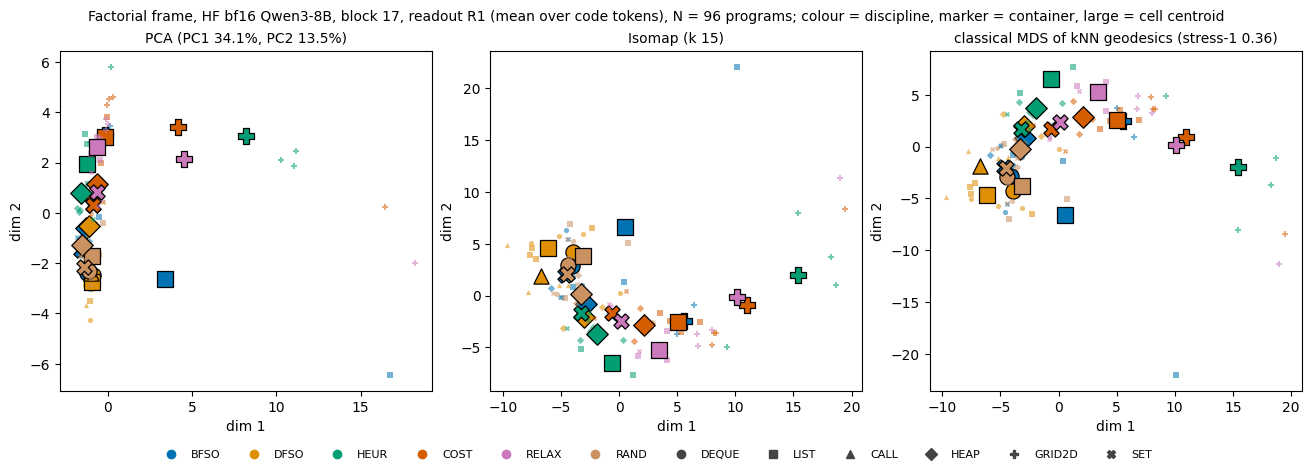

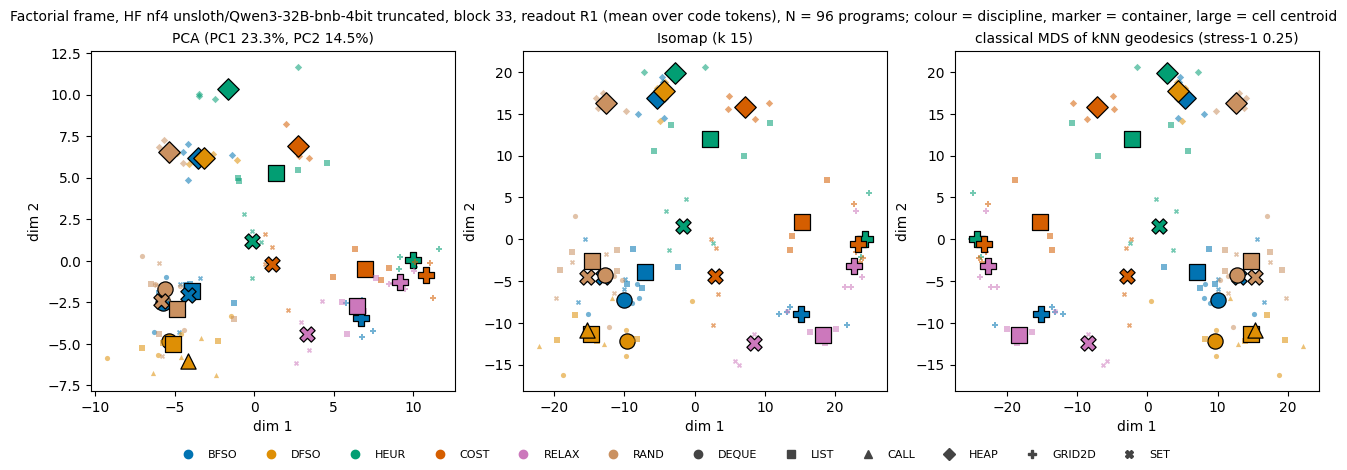

In [23]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for t in MODEL_TAGS:
        fig_factorial(t, {"8b": "F1_factorial_8b", "32b": "F2_factorial_32b"}[t])

**F5: G1 bars.** ρ_dc (discipline | container) and ρ_cd (container | discipline), with 95% program-bootstrap CIs, for all cells and for the crossed core. The E0 and RANDNET baselines and the noise ceiling are drawn alongside, and the dotted line is the pre-registered 0.30 threshold. The values are read from the `g1_<model>.json` files written in section 4.

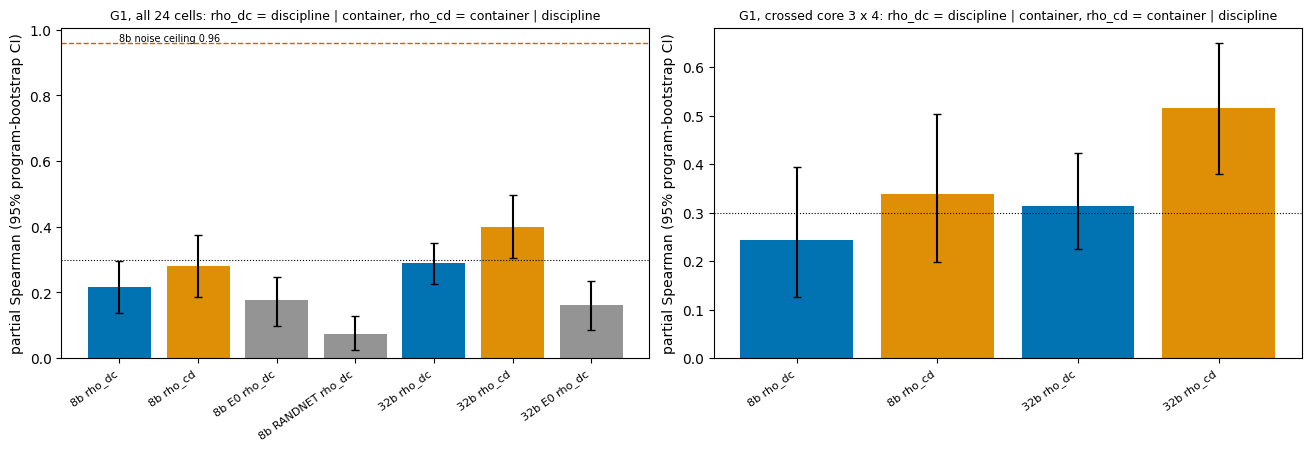

In [24]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    fig_g1_bars("F5_g1_bars")

**F7: G1 layer curve.** ρ_dc and ρ_cd at every kept block, plotted against relative depth. In the full run the curve is flat: discipline is no better encoded at any other depth.

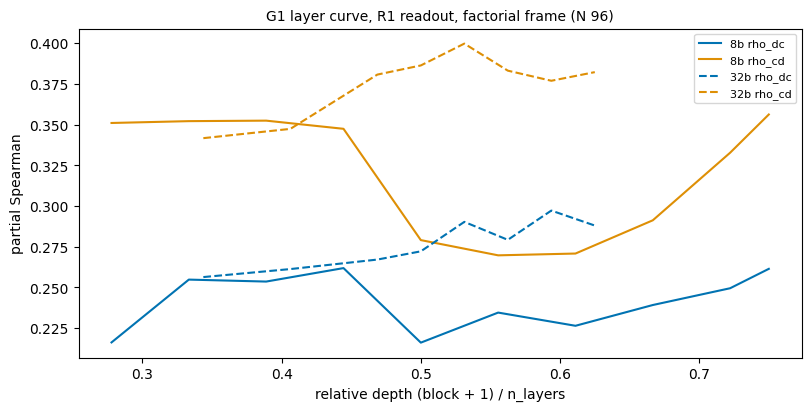

figures written to tpg2/figures


In [25]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    fig_layer("F7_layer_curve")
print("figures written to", FIG.relative_to(Path.cwd()))

## 7. Independent audit (`audit/rederive.py`, G1 part)

The audit recomputes ρ_dc, ρ_cd and δ from `results/pairs_<model>.csv` using **only the standard library**: its own average ranks, closed-form OLS residuals and Pearson correlation, with no numpy or scipy. The G2 and frozen-count parts of the audit need the placement CSVs and the full program files, so only the G1 part runs here. A mismatch above 1e-6 would mean the numpy pipeline and the re-derivation disagree.

In [26]:
# ---- audit/rederive.py (stdlib only, no numpy): helpers + the G1 part of main() ----
ROOT = v10.ROOT          # original: Path(__file__).resolve().parent.parent (the folder that holds results/)
TOL = 1e-9


def ranks(v):
    order = sorted(range(len(v)), key=lambda i: v[i])
    r = [0.0] * len(v)
    i = 0
    while i < len(order):
        j = i
        while j + 1 < len(order) and v[order[j + 1]] == v[order[i]]:
            j += 1
        avg = (i + j) / 2.0 + 1.0
        for k in range(i, j + 1):
            r[order[k]] = avg
        i = j + 1
    return r


def resid(y, z):
    """Residuals of y on [1, z] by closed-form simple OLS."""
    n = len(y)
    my, mz = sum(y) / n, sum(z) / n
    szz = sum((a - mz) ** 2 for a in z)
    szy = sum((a - mz) * (b - my) for a, b in zip(z, y))
    b1 = szy / szz if szz > 0 else 0.0
    b0 = my - b1 * mz
    return [b - (b0 + b1 * a) for a, b in zip(z, y)]


def pearson(a, b):
    n = len(a)
    ma, mb = sum(a) / n, sum(b) / n
    sab = sum((x - ma) * (y - mb) for x, y in zip(a, b))
    saa = sum((x - ma) ** 2 for x in a)
    sbb = sum((y - mb) ** 2 for y in b)
    return sab / math.sqrt(saa * sbb) if saa > 0 and sbb > 0 else float("nan")


def partial(y, x, z):
    ry, rx, rz = ranks(y), ranks(x), ranks(z)
    return pearson(resid(ry, rz), resid(rx, rz))


out = {"g1": {}, "g2": {}, "counts": {}, "mismatches": []}
for tag in ("8b", "32b"):
    p = ROOT / f"results/pairs_{tag}.csv"
    if not p.exists():
        continue
    DS, DD, DC = [], [], []
    with p.open() as fh:
        for row in csv.DictReader(fh):
            DS.append(float(row["D_S"]))
            DD.append(float(row["D_disc"]))
            DC.append(float(row["D_cont"]))
    rdc, rcd = partial(DS, DD, DC), partial(DS, DC, DD)
    ref = json.loads((ROOT / f"results/g1_{tag}.json").read_text())["primary"]
    rec = {"rho_dc": rdc, "rho_cd": rcd, "delta": rdc - rcd, "ref_rho_dc": ref["rho_dc"],
           "ref_rho_cd": ref["rho_cd"], "ref_delta": ref["delta"], "n_pairs": len(DS)}
    for k in ("rho_dc", "rho_cd", "delta"):
        d = abs(rec[k] - rec["ref_" + k])
        rec[f"absdiff_{k}"] = d
        if d > 1e-6:          # pairs CSV stores D_S at 10 significant digits
            out["mismatches"].append(f"g1 {tag} {k}: {rec[k]} vs {rec['ref_' + k]}")
    out["g1"][tag] = rec
    # (G2 r_F and frozen-count checks need results/geo_class_dist_<model>.csv and the full program files)
out["n_mismatches"] = len(out["mismatches"])
print(json.dumps({"n_mismatches": out["n_mismatches"], "g1": {t: {k: v for k, v in r.items()
                                                               if k.startswith(("rho", "delta", "absdiff"))}
                                                           for t, r in out["g1"].items()}}, indent=1))

{
 "n_mismatches": 0,
 "g1": {
  "8b": {
   "rho_dc": 0.21609189288512756,
   "rho_cd": 0.27907570613028704,
   "delta": -0.06298381324515948,
   "absdiff_rho_dc": 0.0,
   "absdiff_rho_cd": 2.220446049250313e-16,
   "absdiff_delta": 2.220446049250313e-16
  },
  "32b": {
   "rho_dc": 0.29026803033181936,
   "rho_cd": 0.39977589976401284,
   "delta": -0.10950786943219348,
   "absdiff_rho_dc": 2.220446049250313e-16,
   "absdiff_rho_cd": 3.3306690738754696e-16,
   "absdiff_delta": 1.1102230246251565e-16
  }
 }
}


## 8. Results: demo subset vs full run, and the G2 frame maps

- **G1 table:** the statistics on the 96-program subset next to the full run (N = 287, read from `metadata.full_run_reference`).
- **G2 tables:** the leave-one-out accuracy of the demo frame next to the full-run frame, then the survivor-placement predictions. Those exist only in the full run, because the 351 placed programs are not in the demo data.
- **Figure:**
  - (a) G1, demo vs full run;
  - (b, c) each model's G2 frame in activation coordinates: classical MDS of the kNN geodesics, with cell centroids. Banned cells have a black edge. Non-banned cells are labelled by their class-g call: E = EDGE, M = MIDDLE (the median class itself), O = OPPOSITE.

In [27]:
REF = data["metadata"]["full_run_reference"]


def ci_txt(c):
    return "[{:.3f}, {:.3f}]".format(*c)


print(f"G1 -- demo subset (N = {len(data['examples'])}) vs full run (N = {REF['g1']['8b']['n_programs']})")
hdr = f"{'model':<6}{'statistic':<28}{'demo':>8}{'demo 95% CI':>18}{'full run':>10}{'full 95% CI':>18}"
print(hdr)
print("-" * len(hdr))
for t, r in g1_results.items():
    ref = REF["g1"][t]
    rows_ = [("rho_dc  disc | cont", "primary", "rho_dc"), ("rho_cd  cont | disc", "primary", "rho_cd"),
             ("delta = rho_dc - rho_cd", "primary", "delta"), ("S1 crossed core rho_dc", "S1_crossed_core", "rho_dc"),
             ("S1 crossed core rho_cd", "S1_crossed_core", "rho_cd"), ("S7 E0 rho_dc", "S7_E0_bag_of_tokens", "rho_dc"),
             ("S7 RANDNET rho_dc", "S7_RANDNET_block17", "rho_dc"), ("S6 readout R2 rho_dc", "S6_readout_R2", "rho_dc")]
    for lab, key, k in rows_:
        if key not in r or key not in ref:
            continue
        print(f"{t:<6}{lab:<28}{r[key][k]:>8.3f}{ci_txt(r[key]['bootstrap'][k]['ci95']):>18}"
              f"{ref[key][k]:>10.3f}{ci_txt(ref[key]['ci95'][k]):>18}")
    p = r["primary"]
    print(f"{t:<6}{'perm p  rho_dc | rho_cd':<28}{p['perm_rho_dc']['p']:>8.4f}{p['perm_rho_cd']['p']:>18.4f}"
          f"{ref['primary']['perm_rho_dc_p']:>10.4f}{ref['primary']['perm_rho_cd_p']:>18.4f}")
    sp, sf = r["S2_rank_regression"]["semi_partial"], ref["S2_rank_regression"]["semi_partial"]
    print(f"{t:<6}{'S2 semi-partial surf | len':<28}{sp['D_surf']:>8.2f}{sp['D_len']:>18.2f}{sf['D_surf']:>10.2f}"
          f"{sf['D_len']:>18.2f}")
    print(f"{t:<6}{'S2 semi-partial disc | cont':<28}{sp['D_disc']:>8.2f}{sp['D_cont']:>18.2f}{sf['D_disc']:>10.2f}"
          f"{sf['D_cont']:>18.2f}")
    if "S9_noise_ceiling" in r and "S9_noise_ceiling" in ref:
        print(f"{t:<6}{'S9 noise ceiling':<28}{r['S9_noise_ceiling']['spearman_DS_ctx_v_vs_ctx_v+1']:>8.3f}"
              f"{'':>18}{ref['S9_noise_ceiling']:>10.3f}")
print(f"\nG1 verdict -- demo: {verdict['verdict']}  ({verdict['why']})")
print(f"G1 verdict -- full run: {REF['g1_verdict']['verdict']}  ({REF['g1_verdict']['why']})")

print("\nG2 frame leave-one-out -- demo frame (96 factorial programs, 24 cells) vs full-run frame (464 programs, "
      "24 cells + 10 catalogue classes)")
for t, r in g2_results.items():
    lo, lf = r["frame_loo"], REF["g2"][t]["frame_loo"]
    print(f"{t:<5} class LOO {lo['class_loo_accuracy']:.3f} (chance {lo['chance_class']:.3f}) vs "
          f"{lf['class_loo_accuracy']:.3f} (chance {lf['chance_class']:.3f}) | discipline LOO "
          f"{lo['discipline_loo_accuracy']:.3f} vs {lf['discipline_loo_accuracy']:.3f} | false-inside "
          f"{lo['false_inside_rate']:.3f} vs {lf['false_inside_rate']:.3f}")

print("\nG2 survivor placement on the full-run frame (full run only; the 351 placed programs are not in the demo data)")
for t, g in REF["g2"].items():
    pu, pb, pc = g["P-UD"], g["P-BF"], g["P-COV"]
    print(f"{t:<5} P-UD  unit-weight Dijkstra (n {g['families_full']['F-UD']['n']}): r_F {pu['full_frame']['r_F']:.2f} "
          f"{pu['full_frame']['verdict']} (robust {pu['full_frame']['robust']}); HEAP frame "
          f"{pu['heap_frame']['verdict']} -> supported {pu['supported']}")
    print(f"      P-BF  grid Bellman-Ford (n {g['families_full']['F-BF']['n']}): r_F {pb['full_frame']['r_F']:.2f} "
          f"{pb['full_frame']['verdict']} (robust {pb['full_frame']['robust']}); share nearest RELAX "
          f"{pb['share_nearest_discipline_RELAX']:.2f} -> supported {pb['supported']}")
    print(f"      P-COV covert BFS/DFS (n {pc['n']}): share nearest banned class {pc['share_nearest_banned']:.3f}"
          f" -> supported {pc['supported']}")

G1 -- demo subset (N = 96) vs full run (N = 287)
model statistic                       demo       demo 95% CI  full run       full 95% CI
----------------------------------------------------------------------------------------
8b    rho_dc  disc | cont            0.216    [0.138, 0.295]     0.226    [0.186, 0.265]
8b    rho_cd  cont | disc            0.279    [0.186, 0.375]     0.300    [0.251, 0.351]
8b    delta = rho_dc - rho_cd       -0.063   [-0.182, 0.057]    -0.074  [-0.133, -0.018]
8b    S1 crossed core rho_dc         0.243    [0.126, 0.395]     0.280    [0.218, 0.357]
8b    S1 crossed core rho_cd         0.338    [0.197, 0.503]     0.366    [0.293, 0.457]
8b    S7 E0 rho_dc                   0.177    [0.097, 0.248]     0.169    [0.132, 0.205]
8b    S7 RANDNET rho_dc              0.073    [0.025, 0.127]     0.072    [0.045, 0.095]
8b    S6 readout R2 rho_dc           0.100    [0.032, 0.183]     0.092    [0.054, 0.133]
8b    perm p  rho_dc | rho_cd       0.0005            0.0005 

The final figure: (a) G1 on the demo subset vs the full run, then the G2 frame of each model in activation coordinates.

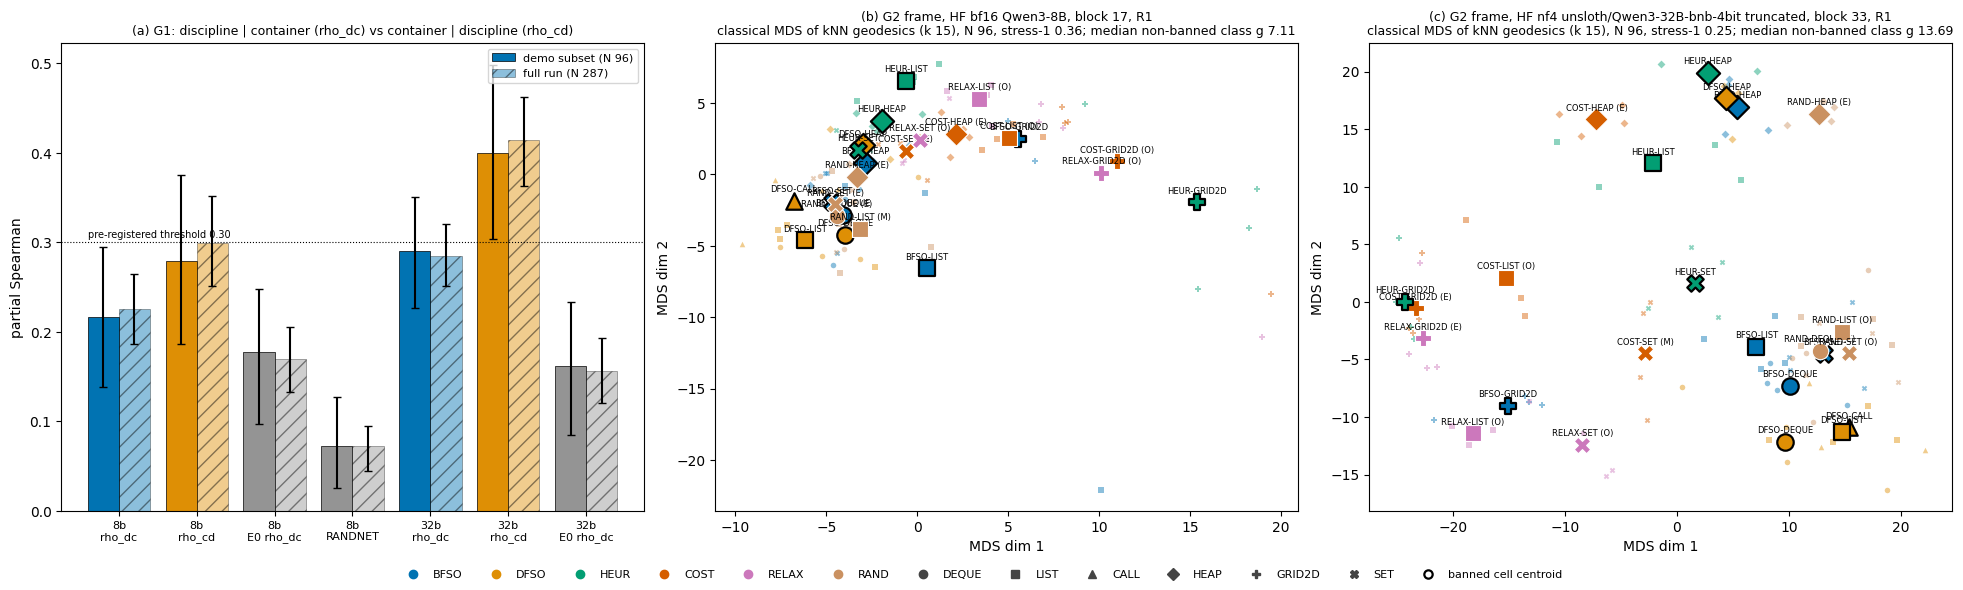

In [28]:
nf = len(g2_frames)
fig, axs = plt.subplots(1, 1 + nf, figsize=(6.5 + 6.5 * nf, 5.8), layout="constrained")
axs = np.atleast_1d(axs)

# (a) G1: demo subset vs full run (error bars = 95% program-bootstrap CIs)
ax = axs[0]
groups = []
for t, r in g1_results.items():
    ref = REF["g1"][t]
    for key, stat, lab in (("primary", "rho_dc", "rho_dc"), ("primary", "rho_cd", "rho_cd"),
                           ("S7_E0_bag_of_tokens", "rho_dc", "E0 rho_dc"), ("S7_RANDNET_block17", "rho_dc", "RANDNET")):
        if key in r and key in ref:
            groups.append((f"{t}\n{lab}", r[key][stat], r[key]["bootstrap"][stat]["ci95"], ref[key][stat],
                           ref[key]["ci95"][stat], PALETTE[0] if stat == "rho_dc" and key == "primary" else
                           PALETTE[1] if stat == "rho_cd" else PALETTE[7]))
x = np.arange(len(groups))
for off, which, alpha, hatch in ((-0.2, "demo", 1.0, None), (0.2, "full", 0.45, "//")):
    vals = [g[1] if which == "demo" else g[3] for g in groups]
    cis = [g[2] if which == "demo" else g[4] for g in groups]
    err = np.abs(np.array([[v - c[0], c[1] - v] for v, c in zip(vals, cis)]).T)
    ax.bar(x + off, vals, width=0.4, color=[g[5] for g in groups], alpha=alpha, hatch=hatch, yerr=err, capsize=3,
           edgecolor="black", linewidth=0.5, label=f"demo subset (N {len(data['examples'])})" if which == "demo"
           else f"full run (N {REF['g1']['8b']['n_programs']})")
ax.axhline(0.30, color="black", lw=0.8, ls=":")
ax.annotate("pre-registered threshold 0.30", (-0.4, 0.305), fontsize=7)
ax.set_xticks(x, [g[0] for g in groups], fontsize=8)
ax.set_ylabel("partial Spearman")
ax.set_title("(a) G1: discipline | container (rho_dc) vs container | discipline (rho_cd)", fontsize=9)
ax.legend(fontsize=8, loc="upper right")

# (b, c) G2 frames: classical MDS of the kNN geodesics of the 96-program frame (activation coordinates)
for ax, (t, full), letter in zip(axs[1:], g2_frames.items(), "bc"):
    M = geometry.classical_mds(full.geo)
    s1 = geometry.stress1(full.geo, M)
    cls, med = geometry.classify(full.class_g)
    for c in full.classes:
        sel = full.labels == c
        col, mk = DISC_COL[g2.disc_of(c)], CONT_MK.get(g2.cont_of(c), "o")
        ax.scatter(M[sel, 0], M[sel, 1], s=16, marker=mk, color=col, alpha=0.45, linewidths=0)
        cx, cy = M[sel].mean(0)
        banned = g2.is_banned(c)
        ax.scatter([cx], [cy], s=140, marker=mk, color=col, edgecolors="black" if banned else "white",
                   linewidths=1.6 if banned else 0.8, zorder=3)
        ax.annotate(c if banned else f"{c} ({cls[c][0]})", (cx, cy), fontsize=6, ha="center", va="bottom",
                    xytext=(0, 5), textcoords="offset points")
    ax.set_title(f"({letter}) G2 frame, {v10.MODELS[t]['engine']}, block {v10.MODELS[t]['primary_block']}, R1\n"
                 f"classical MDS of kNN geodesics (k {full.k}), N {len(full.X)}, stress-1 {s1:.2f}; "
                 f"median non-banned class g {med:.2f}", fontsize=9)
    ax.set_xlabel("MDS dim 1")
    ax.set_ylabel("MDS dim 2")
hd = [plt.Line2D([], [], color=DISC_COL[d], marker="o", ls="", label=d) for d in
      ("BFSO", "DFSO", "HEUR", "COST", "RELAX", "RAND")]
hc = [plt.Line2D([], [], color="#444444", marker=mk, ls="", label=c) for c, mk in CONT_MK.items()]
hb = [plt.Line2D([], [], color="white", marker="o", markeredgecolor="black", markeredgewidth=1.6, ls="",
                 label="banned cell centroid")]
fig.legend(handles=hd + hc + hb, loc="outside lower center", ncol=13, fontsize=8, frameon=False)
plt.show()